In [1]:
import sys
import requests, pandas, matplotlib, seaborn, dotenv, schedule

print("Python path:", sys.executable)
print("requests:", requests.__version__)
print("pandas:", pandas.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", seaborn.__version__)
print("All packages imported successfully")

Python path: c:\Users\laize\OneDrive\Famola\Training\Python For Banking & Finance Analytics with AI\BOT_Live_Data_Assignment\venv\Scripts\python.exe
requests: 2.34.2
pandas: 3.0.6
matplotlib: 3.11.2
seaborn: 0.13.2
All packages imported successfully


In [1]:
from pathlib import Path
import json

project = Path.cwd()
print("Project folder:", project.name)

# Folders and files we expect from Stage 0
expected = [
    "charts", "Data", "Data/raw", "Logs", "Reports", "screenshots",
    "config.json", ".env", ".env.example", "requirements.txt",
]

for item in expected:
    status = "OK     " if (project / item).exists() else "MISSING"
    print(status, item)

# Make sure config.json is valid JSON
with open(project / "config.json") as f:
    config = json.load(f)
print("config.json loaded. Pairs:", [p["base"] + "/" + p["quote"] for p in config["pairs"]])

Project folder: BOT_Live_Data_Assignment
OK      charts
OK      Data
OK      Data/raw
OK      Logs
OK      Reports
OK      screenshots
OK      config.json
OK      .env
OK      .env.example
OK      requirements.txt
config.json loaded. Pairs: ['USD/TZS', 'EUR/TZS', 'GBP/TZS']


In [2]:
import json
from pathlib import Path

PROJECT = Path.cwd()

with open(PROJECT / "config.json") as f:
    CONFIG = json.load(f)

BASE_URL = CONFIG["api"]["base_url"]
PROVIDER = CONFIG["api"]["provider"]
TIMEOUT = CONFIG["api"]["timeout_seconds"]
PAIRS = [(p["base"], p["quote"]) for p in CONFIG["pairs"]]

print("Base URL:", BASE_URL)
print("Provider:", PROVIDER)
print("Timeout:", TIMEOUT)
print("Pairs:", PAIRS)

Base URL: https://api.frankfurter.dev/v2
Provider: BOTA
Timeout: 15
Pairs: [('USD', 'TZS'), ('EUR', 'TZS'), ('GBP', 'TZS')]


In [3]:
import requests

url = f"{BASE_URL}/rate/USD/TZS"
params = {"providers": PROVIDER}

response = requests.get(url, params=params, timeout=TIMEOUT)

print("Status code:", response.status_code)
print("Final URL:", response.url)
print("Raw text:", response.text)

Status code: 200
Final URL: https://api.frankfurter.dev/v2/rate/USD/TZS?providers=BOTA
Raw text: {"date":"2026-10-14","base":"USD","quote":"TZS","rate":2631.4283}


In [4]:
from datetime import datetime

data = response.json()

rate_date = datetime.strptime(data.get("date"), "%Y-%m-%d").date()
base = data.get("base")
quote = data.get("quote")
rate = float(data.get("rate"))

print("Data:", data)
print("Date:", rate_date, type(rate_date))
print("Pair:", base, "/", quote)
print("Rate:", rate, type(rate))

Data: {'date': '2026-10-14', 'base': 'USD', 'quote': 'TZS', 'rate': 2631.4283}
Date: 2026-10-14 <class 'datetime.date'>
Pair: USD / TZS
Rate: 2631.4283 <class 'float'>


In [5]:
def fetch_latest(base, quote):
    """Fetch the latest BOTA rate for one pair. Returns a dict, or None if it fails."""
    url = f"{BASE_URL}/rate/{base}/{quote}"
    params = {"providers": PROVIDER}
    try:
        response = requests.get(url, params=params, timeout=TIMEOUT)
        response.raise_for_status()
        data = response.json()
        if data.get("rate") is None:
            print(f"No rate in answer for {base}/{quote}: {data}")
            return None
        return {
            "date": datetime.strptime(data.get("date"), "%Y-%m-%d").date(),
            "base": data.get("base"),
            "quote": data.get("quote"),
            "rate": float(data.get("rate")),
        }
    except requests.exceptions.RequestException as error:
        print(f"Request failed for {base}/{quote}: {error}")
        return None
    except (ValueError, TypeError) as error:
        print(f"Bad data for {base}/{quote}: {error}")
        return None


for base, quote in PAIRS:
    print(fetch_latest(base, quote))

{'date': datetime.date(2026, 10, 14), 'base': 'USD', 'quote': 'TZS', 'rate': 2631.4283}
{'date': datetime.date(2026, 10, 14), 'base': 'EUR', 'quote': 'TZS', 'rate': 2941.9369}
{'date': datetime.date(2026, 10, 14), 'base': 'GBP', 'quote': 'TZS', 'rate': 3482.9585}


In [6]:
from datetime import date, timedelta

today = date.today()
start = today - timedelta(days=45)

url = f"{BASE_URL}/rates"
params = {
    "from": start.isoformat(),
    "to": today.isoformat(),
    "base": "USD",
    "quotes": "TZS",
    "providers": PROVIDER,
}

response = requests.get(url, params=params, timeout=TIMEOUT)
print("Status code:", response.status_code)
print("Final URL:", response.url)

history = response.json()
print("Type:", type(history))
print("Records:", len(history))
print("First 3:", history[:3])
print("Last 3:", history[-3:])

Status code: 200
Final URL: https://api.frankfurter.dev/v2/rates?from=2026-08-30&to=2026-10-14&base=USD&quotes=TZS&providers=BOTA
Type: <class 'list'>
Records: 46
First 3: [{'date': '2026-08-30', 'base': 'USD', 'quote': 'TZS', 'rate': 2639.8763}, {'date': '2026-08-31', 'base': 'USD', 'quote': 'TZS', 'rate': 2639.8763}, {'date': '2026-09-01', 'base': 'USD', 'quote': 'TZS', 'rate': 2639.8763}]
Last 3: [{'date': '2026-10-12', 'base': 'USD', 'quote': 'TZS', 'rate': 2630.891}, {'date': '2026-10-13', 'base': 'USD', 'quote': 'TZS', 'rate': 2630.891}, {'date': '2026-10-14', 'base': 'USD', 'quote': 'TZS', 'rate': 2631.4283}]


In [7]:
import pandas as pd

HISTORY_DAYS = CONFIG["history_days"]


def fetch_history(base, quote, lookback_days=45):
    """Fetch daily BOTA rates for one pair. Returns a list of records, or None if it fails."""
    today = date.today()
    start = today - timedelta(days=lookback_days)
    url = f"{BASE_URL}/rates"
    params = {
        "from": start.isoformat(),
        "to": today.isoformat(),
        "base": base,
        "quotes": quote,
        "providers": PROVIDER,
    }
    try:
        response = requests.get(url, params=params, timeout=TIMEOUT)
        response.raise_for_status()
        records = response.json()
        if not isinstance(records, list) or len(records) == 0:
            print(f"No history returned for {base}/{quote}: {records}")
            return None
        return records
    except requests.exceptions.RequestException as error:
        print(f"History request failed for {base}/{quote}: {error}")
        return None
    except ValueError as error:
        print(f"Bad history data for {base}/{quote}: {error}")
        return None


frames = []
for base, quote in PAIRS:
    records = fetch_history(base, quote)
    if records is None:
        continue
    df = pd.DataFrame(records)
    df["date"] = pd.to_datetime(df["date"])
    df["rate"] = df["rate"].astype(float)
    df = df.sort_values("date").tail(HISTORY_DAYS)
    frames.append(df)

history_df = pd.concat(frames, ignore_index=True)

print(history_df.groupby(["base", "quote"]).size())
print(history_df.head())
print(history_df.dtypes)

base  quote
EUR   TZS      30
GBP   TZS      30
USD   TZS      30
dtype: int64
        date base quote       rate
0 2026-09-15  USD   TZS  2641.1898
1 2026-09-16  USD   TZS  2641.1898
2 2026-09-17  USD   TZS  2641.2694
3 2026-09-18  USD   TZS  2641.5878
4 2026-09-19  USD   TZS  2641.3390
date     datetime64[us]
base                str
quote               str
rate            float64
dtype: object


In [8]:
def fetch_data():
    """Fetch the latest 30 daily BOTA rates for every pair in config.json.
    Returns one pandas table with columns: date, base, quote, rate."""
    frames = []
    for base, quote in PAIRS:
        records = fetch_history(base, quote)
        if records is None:
            continue
        df = pd.DataFrame(records)
        df["date"] = pd.to_datetime(df["date"])
        df["rate"] = df["rate"].astype(float)
        frames.append(df.sort_values("date").tail(HISTORY_DAYS))
    if not frames:
        return pd.DataFrame(columns=["date", "base", "quote", "rate"])
    return pd.concat(frames, ignore_index=True)


data_df = fetch_data()

print("Rows:", len(data_df))
print(data_df.groupby(["base", "quote"])["rate"].agg(["count", "min", "max", "last"]))

Rows: 90
            count        min        max       last
base quote                                        
EUR  TZS       30  2941.9369  3048.8172  2941.9369
GBP  TZS       30  3476.1904  3562.5441  3482.9585
USD  TZS       30  2630.8910  2646.2347  2631.4283


In [9]:
import sqlite3

DB_PATH = PROJECT / CONFIG["files"]["database"]

conn = sqlite3.connect(DB_PATH)

conn.execute("""
    CREATE TABLE IF NOT EXISTS fx_rates (
        date            TEXT NOT NULL,
        base            TEXT NOT NULL,
        quote           TEXT NOT NULL,
        rate            REAL NOT NULL,
        fetched_at_utc  TEXT NOT NULL,
        PRIMARY KEY (date, base, quote)
    )
""")
conn.commit()

tables = conn.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()
print("Database file:", DB_PATH)
print("Tables:", tables)

Database file: c:\Users\laize\OneDrive\Famola\Training\Python For Banking & Finance Analytics with AI\BOT_Live_Data_Assignment\Data\fx_rates.db
Tables: [('fx_rates',)]


In [10]:
import json
from datetime import datetime, timezone

RAW_DIR = PROJECT / CONFIG["folders"]["raw"]
RAW_DIR.mkdir(parents=True, exist_ok=True)


def save_raw_json(records, base, quote):
    """Save the API answer for one pair as a JSON file in Data/raw. Returns the file path."""
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    path = RAW_DIR / f"{base}_{quote}_{stamp}.json"
    with open(path, "w", encoding="utf-8") as f:
        json.dump(records, f, indent=2)
    return path


records = fetch_history("USD", "TZS")
if records:
    saved_path = save_raw_json(records, "USD", "TZS")
    print("Saved:", saved_path.name)
    print("Size (bytes):", saved_path.stat().st_size)
    print("Records in file:", len(records))

Saved: USD_TZS_20261014_095433.json
Size (bytes): 4686
Records in file: 46


In [11]:
def save_data(df, conn):
    """Insert the rows of a rates table into fx_rates with a UTC timestamp.
    Rows that already exist (same date, base, quote) are skipped. Returns the number of new rows."""
    fetched_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
    rows = [
        (row.date.strftime("%Y-%m-%d"), row.base, row.quote, float(row.rate), fetched_at)
        for row in df.itertuples(index=False)
    ]
    before = conn.total_changes
    conn.executemany(
        """INSERT OR IGNORE INTO fx_rates (date, base, quote, rate, fetched_at_utc)
           VALUES (?, ?, ?, ?, ?)""",
        rows,
    )
    conn.commit()
    return conn.total_changes - before


first_run = save_data(data_df, conn)
second_run = save_data(data_df, conn)

total = conn.execute("SELECT COUNT(*) FROM fx_rates").fetchone()[0]
print("New rows on first run:", first_run)
print("New rows on second run:", second_run)
print("Total rows in database:", total)

New rows on first run: 90
New rows on second run: 0
Total rows in database: 90


In [12]:
conn.execute("DROP VIEW IF EXISTS fx_rates_clean")

conn.execute("""
    CREATE VIEW fx_rates_clean AS
    SELECT
        date,
        base,
        quote,
        rate,
        fetched_at_utc,
        LAG(rate) OVER w AS prev_rate,
        CASE WHEN rate = LAG(rate) OVER w THEN 1 ELSE 0 END AS is_repeat,
        ROUND((rate - LAG(rate) OVER w) / LAG(rate) OVER w * 100, 4) AS change_pct
    FROM fx_rates
    WHERE rate > 0
    WINDOW w AS (PARTITION BY base, quote ORDER BY date)
""")
conn.commit()

summary = pd.read_sql_query("""
    SELECT base || '/' || quote AS pair,
           COUNT(*)                        AS rows_total,
           SUM(is_repeat)                  AS repeated_rates,
           COUNT(*) - SUM(is_repeat)       AS new_value_days,
           MIN(date)                       AS first_date,
           MAX(date)                       AS last_date
    FROM fx_rates_clean
    GROUP BY base, quote
""", conn)
print(summary)

print(pd.read_sql_query("SELECT * FROM fx_rates_clean WHERE base='USD' ORDER BY date DESC LIMIT 5", conn))

      pair  rows_total  repeated_rates  new_value_days  first_date   last_date
0  EUR/TZS          30               9              21  2026-09-15  2026-10-14
1  GBP/TZS          30               9              21  2026-09-15  2026-10-14
2  USD/TZS          30               9              21  2026-09-15  2026-10-14
         date base quote       rate             fetched_at_utc  prev_rate  \
0  2026-10-14  USD   TZS  2631.4283  2026-10-14T09:56:52+00:00  2630.8910   
1  2026-10-13  USD   TZS  2630.8910  2026-10-14T09:56:52+00:00  2630.8910   
2  2026-10-12  USD   TZS  2630.8910  2026-10-14T09:56:52+00:00  2630.8910   
3  2026-10-11  USD   TZS  2630.8910  2026-10-14T09:56:52+00:00  2631.3587   
4  2026-10-10  USD   TZS  2631.3587  2026-10-14T09:56:52+00:00  2633.6771   

   is_repeat  change_pct  
0          0      0.0204  
1          1      0.0000  
2          1      0.0000  
3          0     -0.0178  
4          0     -0.0880  


In [13]:
checks = {
    "Total rows": "SELECT COUNT(*) FROM fx_rates",
    "Duplicate (date, base, quote) groups": """
        SELECT COUNT(*) FROM (
            SELECT date, base, quote FROM fx_rates
            GROUP BY date, base, quote HAVING COUNT(*) > 1
        )""",
    "Rows with empty values": """
        SELECT COUNT(*) FROM fx_rates
        WHERE date IS NULL OR base IS NULL OR quote IS NULL
           OR rate IS NULL OR fetched_at_utc IS NULL""",
    "Rows with rate <= 0": "SELECT COUNT(*) FROM fx_rates WHERE rate <= 0",
}

for name, sql in checks.items():
    print(f"{name}: {conn.execute(sql).fetchone()[0]}")

print()
print(pd.read_sql_query("""
    SELECT base || '/' || quote AS pair,
           ROUND(MIN(rate), 4) AS min_rate,
           ROUND(MAX(rate), 4) AS max_rate,
           ROUND(AVG(rate), 4) AS avg_rate,
           MIN(fetched_at_utc) AS fetched_at_utc
    FROM fx_rates
    GROUP BY base, quote
""", conn))

Total rows: 90
Duplicate (date, base, quote) groups: 0
Rows with empty values: 0
Rows with rate <= 0: 0

      pair   min_rate   max_rate   avg_rate             fetched_at_utc
0  EUR/TZS  2941.9369  3048.8172  2997.7349  2026-10-14T09:56:52+00:00
1  GBP/TZS  3476.1904  3562.5441  3509.3611  2026-10-14T09:56:52+00:00
2  USD/TZS  2630.8910  2646.2347  2639.8431  2026-10-14T09:56:52+00:00


In [14]:
import logging

LOG_PATH = PROJECT / CONFIG["files"]["log"]
LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

logger = logging.getLogger("fx_automation")
logger.setLevel(logging.INFO)

if not logger.handlers:
    file_handler = logging.FileHandler(LOG_PATH, encoding="utf-8")
    file_handler.setFormatter(
        logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
    )
    logger.addHandler(file_handler)

logger.info("Logging started")
logger.warning("This is a test warning")

print("Log file:", LOG_PATH)
print(LOG_PATH.read_text(encoding="utf-8"))

Log file: c:\Users\laize\OneDrive\Famola\Training\Python For Banking & Finance Analytics with AI\BOT_Live_Data_Assignment\Logs\automation.log
2026-10-14 13:02:42,424 | INFO | Logging started
2026-10-14 13:02:42,425 | WARNING | This is a test warning



In [15]:
import time


def request_with_retry(url, params=None):
    """GET a URL with a timeout. On timeouts, network errors, HTTP 429 or 5xx it waits
    (1s, 2s, 4s ... or the Retry-After header) and tries again, up to max_attempts.
    Returns the response, or None if it gave up or the request itself was wrong."""
    max_attempts = CONFIG["retry"]["max_attempts"]
    base_delay = CONFIG["retry"]["base_delay_seconds"]

    for attempt in range(1, max_attempts + 1):
        wait = base_delay * 2 ** (attempt - 1)
        try:
            response = requests.get(url, params=params, timeout=TIMEOUT)
            if response.status_code == 429 or response.status_code >= 500:
                retry_after = response.headers.get("Retry-After", "")
                if retry_after.isdigit():
                    wait = int(retry_after)
                problem = f"HTTP {response.status_code}"
            else:
                response.raise_for_status()
                return response
        except requests.exceptions.HTTPError as error:
            logger.error(f"Request rejected, not retrying: {error}")
            return None
        except requests.exceptions.RequestException as error:
            problem = type(error).__name__

        if attempt == max_attempts:
            logger.error(f"Giving up after {max_attempts} attempts: {problem}")
            return None
        logger.warning(f"Attempt {attempt} failed ({problem}); waiting {wait}s before retry")
        time.sleep(wait)
    return None


good = request_with_retry(f"{BASE_URL}/rate/USD/TZS", {"providers": PROVIDER})
print("Good request status:", good.status_code if good else None)

bad = request_with_retry(f"{BASE_URL}/rate/XXX/YYY", {"providers": PROVIDER})
print("Wrong request result:", bad)

print()
print("\n".join(LOG_PATH.read_text(encoding="utf-8").splitlines()[-3:]))

Good request status: 200
Wrong request result: None

2026-10-14 13:02:42,424 | INFO | Logging started
2026-10-14 13:02:42,425 | WARNING | This is a test warning
2026-10-14 13:03:47,140 | ERROR | Request rejected, not retrying: 422 Client Error: Unprocessable Entity for url: https://api.frankfurter.dev/v2/rate/XXX/YYY?providers=BOTA


In [16]:
print(LOG_PATH.read_text(encoding="utf-8"))

2026-10-14 13:02:42,424 | INFO | Logging started
2026-10-14 13:02:42,425 | WARNING | This is a test warning
2026-10-14 13:03:47,140 | ERROR | Request rejected, not retrying: 422 Client Error: Unprocessable Entity for url: https://api.frankfurter.dev/v2/rate/XXX/YYY?providers=BOTA



In [17]:
start = time.time()
result = request_with_retry("https://api.frankfurter.invalid/v2/rate/USD/TZS")
elapsed = time.time() - start

print("Result:", result)
print(f"Total time: {elapsed:.1f} seconds")
print()
print("\n".join(LOG_PATH.read_text(encoding="utf-8").splitlines()[-4:]))

Result: None
Total time: 7.2 seconds

2026-10-14 13:07:41,786 | WARNING | Attempt 1 failed (ConnectionError); waiting 1s before retry
2026-10-14 13:07:42,797 | WARNING | Attempt 2 failed (ConnectionError); waiting 2s before retry
2026-10-14 13:07:44,803 | WARNING | Attempt 3 failed (ConnectionError); waiting 4s before retry
2026-10-14 13:07:48,924 | ERROR | Giving up after 4 attempts: ConnectionError


In [18]:
def fetch_latest(base, quote):
    """Fetch the latest BOTA rate for one pair, with retries. Returns a dict, or None."""
    response = request_with_retry(f"{BASE_URL}/rate/{base}/{quote}", {"providers": PROVIDER})
    if response is None:
        return None
    try:
        data = response.json()
        if data.get("rate") is None:
            logger.warning(f"No rate in answer for {base}/{quote}: {data}")
            return None
        return {
            "date": datetime.strptime(data.get("date"), "%Y-%m-%d").date(),
            "base": data.get("base"),
            "quote": data.get("quote"),
            "rate": float(data.get("rate")),
        }
    except (ValueError, TypeError) as error:
        logger.error(f"Bad data for {base}/{quote}: {error}")
        return None


def fetch_history(base, quote, lookback_days=45):
    """Fetch daily BOTA rates for one pair, with retries. Returns a list of records, or None."""
    today = date.today()
    params = {
        "from": (today - timedelta(days=lookback_days)).isoformat(),
        "to": today.isoformat(),
        "base": base,
        "quotes": quote,
        "providers": PROVIDER,
    }
    response = request_with_retry(f"{BASE_URL}/rates", params)
    if response is None:
        return None
    try:
        records = response.json()
    except ValueError as error:
        logger.error(f"Bad history data for {base}/{quote}: {error}")
        return None
    if not isinstance(records, list) or len(records) == 0:
        logger.warning(f"No history returned for {base}/{quote}: {records}")
        return None
    logger.info(f"Fetched {len(records)} records for {base}/{quote}")
    return records


print(fetch_latest("USD", "TZS"))
print("History records:", len(fetch_history("USD", "TZS")))
print()
print("\n".join(LOG_PATH.read_text(encoding="utf-8").splitlines()[-2:]))

{'date': datetime.date(2026, 10, 14), 'base': 'USD', 'quote': 'TZS', 'rate': 2631.4283}
History records: 46

2026-10-14 13:07:48,924 | ERROR | Giving up after 4 attempts: ConnectionError
2026-10-14 13:08:36,979 | INFO | Fetched 46 records for USD/TZS


In [19]:
def fetch_data():
    """Fetch the latest 30 daily BOTA rates for every pair in config.json, save the raw JSON,
    and return one pandas table with columns: date, base, quote, rate."""
    frames = []
    for base, quote in PAIRS:
        records = fetch_history(base, quote)
        if records is None:
            continue
        save_raw_json(records, base, quote)
        df = pd.DataFrame(records)
        df["date"] = pd.to_datetime(df["date"])
        df["rate"] = df["rate"].astype(float)
        frames.append(df.sort_values("date").tail(HISTORY_DAYS))
    if not frames:
        return pd.DataFrame(columns=["date", "base", "quote", "rate"])
    return pd.concat(frames, ignore_index=True)


def run_once():
    """Run one full cycle: fetch, store and log. Returns the number of new rows saved."""
    logger.info("Run started")
    df = fetch_data()
    if df.empty:
        logger.error("Run finished with no data")
        return 0
    pairs_fetched = df[["base", "quote"]].drop_duplicates().shape[0]
    new_rows = save_data(df, conn)
    logger.info(
        f"Run finished: pairs fetched {pairs_fetched}/{len(PAIRS)}, "
        f"rows received {len(df)}, new rows saved {new_rows}"
    )
    return new_rows


run_once()
run_once()

print("\n".join(LOG_PATH.read_text(encoding="utf-8").splitlines()[-10:]))

2026-10-15 05:33:02,555 | INFO | Run started
2026-10-15 05:33:03,271 | INFO | Fetched 45 records for USD/TZS
2026-10-15 05:33:03,820 | INFO | Fetched 45 records for EUR/TZS
2026-10-15 05:33:04,340 | INFO | Fetched 45 records for GBP/TZS
2026-10-15 05:33:04,400 | INFO | Run finished: pairs fetched 3/3, rows received 90, new rows saved 0
2026-10-15 05:33:04,400 | INFO | Run started
2026-10-15 05:33:04,518 | INFO | Fetched 45 records for USD/TZS
2026-10-15 05:33:04,717 | INFO | Fetched 45 records for EUR/TZS
2026-10-15 05:33:04,829 | INFO | Fetched 45 records for GBP/TZS
2026-10-15 05:33:04,839 | INFO | Run finished: pairs fetched 3/3, rows received 90, new rows saved 0


In [20]:
SHORT_WINDOW = CONFIG["alerts"]["short_ma_window"]
LONG_WINDOW = CONFIG["alerts"]["long_ma_window"]


def load_rates():
    """Read the clean rates from the database, add moving averages. Returns a pandas table."""
    df = pd.read_sql_query(
        "SELECT date, base, quote, rate, is_repeat, change_pct FROM fx_rates_clean ORDER BY base, quote, date",
        conn,
    )
    df["date"] = pd.to_datetime(df["date"])
    df["pair"] = df["base"] + "/" + df["quote"]
    grouped = df.groupby("pair")["rate"]
    df["ma_short"] = grouped.transform(lambda s: s.rolling(SHORT_WINDOW).mean())
    df["ma_long"] = grouped.transform(lambda s: s.rolling(LONG_WINDOW).mean())
    return df


rates_df = load_rates()

print("Rows:", len(rates_df))
print(rates_df[rates_df["pair"] == "USD/TZS"].tail(5)[["date", "rate", "change_pct", "ma_short", "ma_long"]])

Rows: 90
         date       rate  change_pct    ma_short      ma_long
85 2026-10-10  2631.3587     -0.0880  2635.41846  2641.170850
86 2026-10-11  2630.8910     -0.0178  2633.74678  2640.655415
87 2026-10-12  2630.8910      0.0000  2632.47710  2640.139980
88 2026-10-13  2630.8910      0.0000  2631.54176  2639.591710
89 2026-10-14  2631.4283      0.0204  2631.09200  2638.899155


In [21]:
DAILY_LIMIT = CONFIG["alerts"]["daily_change_percent"]


def check_alerts(df, last_n_days=1):
    """Check the newest rows against two rules: a daily change above the limit, and a
    5-day / 20-day moving-average crossover. Prints and logs each alert. Returns a list of alerts."""
    alerts = []
    for pair, g in df.groupby("pair"):
        g = g.sort_values("date").reset_index(drop=True)
        g["gap"] = g["ma_short"] - g["ma_long"]
        g["prev_gap"] = g["gap"].shift(1)

        for _, row in g.tail(last_n_days).iterrows():
            day = row["date"].strftime("%Y-%m-%d")

            if pd.notna(row["change_pct"]) and abs(row["change_pct"]) > DAILY_LIMIT:
                alerts.append({
                    "date": day, "pair": pair, "rule": "Daily change",
                    "message": f"{pair} moved {row['change_pct']:+.4f}% on {day} (limit {DAILY_LIMIT}%)",
                })

            if pd.notna(row["gap"]) and pd.notna(row["prev_gap"]) and row["gap"] * row["prev_gap"] < 0:
                direction = "above" if row["gap"] > 0 else "below"
                alerts.append({
                    "date": day, "pair": pair, "rule": "Moving-average crossover",
                    "message": f"{pair} {SHORT_WINDOW}-day average crossed {direction} the "
                               f"{LONG_WINDOW}-day average on {day}",
                })

    for alert in alerts:
        print("ALERT:", alert["message"])
        logger.warning(f"ALERT | {alert['rule']} | {alert['message']}")
    return alerts


print("--- Latest day only ---")
latest_alerts = check_alerts(rates_df, last_n_days=1)
print("Alerts today:", len(latest_alerts))

print()
print("--- Replay of all 30 days (test) ---")
history_alerts = check_alerts(rates_df, last_n_days=30)
print("Alerts in 30 days:", len(history_alerts))

--- Latest day only ---
Alerts today: 0

--- Replay of all 30 days (test) ---
ALERT: EUR/TZS moved -0.6675% on 2026-10-03 (limit 0.5%)
ALERT: EUR/TZS moved -0.7466% on 2026-10-09 (limit 0.5%)
ALERT: GBP/TZS moved -0.6334% on 2026-09-19 (limit 0.5%)
ALERT: GBP/TZS moved -0.5151% on 2026-09-25 (limit 0.5%)
ALERT: GBP/TZS moved -0.5116% on 2026-10-03 (limit 0.5%)
ALERT: GBP/TZS moved -0.6214% on 2026-10-09 (limit 0.5%)
Alerts in 30 days: 6


In [22]:
columns = [row[1] for row in conn.execute("PRAGMA table_info(fx_rates)")]
if "is_filled" not in columns:
    conn.execute("ALTER TABLE fx_rates ADD COLUMN is_filled INTEGER NOT NULL DEFAULT 0")

conn.execute("DROP VIEW IF EXISTS fx_rates_clean")
conn.execute("""
    CREATE VIEW fx_rates_clean AS
    SELECT
        date,
        base,
        quote,
        rate,
        is_filled,
        fetched_at_utc,
        LAG(rate) OVER w AS prev_rate,
        CASE WHEN rate = LAG(rate) OVER w THEN 1 ELSE 0 END AS is_repeat,
        ROUND((rate - LAG(rate) OVER w) / LAG(rate) OVER w * 100, 4) AS change_pct
    FROM fx_rates
    WHERE rate > 0
    WINDOW w AS (PARTITION BY base, quote ORDER BY date)
""")
conn.commit()

print(pd.read_sql_query("PRAGMA table_info(fx_rates)", conn)[["name", "type"]])
print("Rows marked as filled:", conn.execute("SELECT COUNT(*) FROM fx_rates WHERE is_filled = 1").fetchone()[0])

             name     type
0            date     TEXT
1            base     TEXT
2           quote     TEXT
3            rate     REAL
4  fetched_at_utc     TEXT
5       is_filled  INTEGER
Rows marked as filled: 0


In [23]:
def fill_missing_days(df):
    """Make sure every calendar day up to today has a rate. A day with no published rate
    gets the previous day's rate and is marked is_filled = 1."""
    df = df.sort_values("date").drop_duplicates("date")
    all_days = pd.date_range(df["date"].min(), pd.Timestamp(date.today()), freq="D")
    df = df.set_index("date").reindex(all_days)
    df["is_filled"] = df["rate"].isna().astype(int)
    df[["base", "quote", "rate"]] = df[["base", "quote", "rate"]].ffill()
    df.index.name = "date"
    return df.reset_index()


def fetch_data():
    """Fetch the latest 30 daily BOTA rates for every pair, save the raw JSON, and fill days
    with no published rate using the previous day's rate. Returns one pandas table with
    columns: date, base, quote, rate, is_filled."""
    frames = []
    for base, quote in PAIRS:
        records = fetch_history(base, quote)
        if records is None:
            continue
        save_raw_json(records, base, quote)
        df = pd.DataFrame(records)
        df["date"] = pd.to_datetime(df["date"])
        df["rate"] = df["rate"].astype(float)
        df = fill_missing_days(df).tail(HISTORY_DAYS)
        filled = int(df["is_filled"].sum())
        if filled:
            logger.info(f"Filled {filled} day(s) with the previous rate for {base}/{quote}")
        frames.append(df)
    if not frames:
        return pd.DataFrame(columns=["date", "base", "quote", "rate", "is_filled"])
    return pd.concat(frames, ignore_index=True)


data_df = fetch_data()

print(data_df.groupby(["base", "quote"]).agg(rows=("rate", "count"), filled=("is_filled", "sum")))
print()
print(data_df[data_df["base"] == "USD"].tail(3))

            rows  filled
base quote              
EUR  TZS      30       1
GBP  TZS      30       1
USD  TZS      30       1

         date base quote       rate  is_filled
27 2026-10-13  USD   TZS  2630.8910          0
28 2026-10-14  USD   TZS  2631.4283          0
29 2026-10-15  USD   TZS  2631.4283          1


In [24]:
def save_data(df, conn):
    """Insert the rows of a rates table into fx_rates with a UTC timestamp. An existing row is
    kept, except a filled row (is_filled = 1), which is replaced when the real rate arrives.
    Returns the number of rows added or updated."""
    fetched_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
    rows = [
        (row.date.strftime("%Y-%m-%d"), row.base, row.quote, float(row.rate), fetched_at, int(row.is_filled))
        for row in df.itertuples(index=False)
    ]
    before = conn.total_changes
    conn.executemany(
        """INSERT INTO fx_rates (date, base, quote, rate, fetched_at_utc, is_filled)
           VALUES (?, ?, ?, ?, ?, ?)
           ON CONFLICT (date, base, quote) DO UPDATE SET
               rate = excluded.rate,
               fetched_at_utc = excluded.fetched_at_utc,
               is_filled = excluded.is_filled
           WHERE fx_rates.is_filled = 1 AND excluded.is_filled = 0""",
        rows,
    )
    conn.commit()
    return conn.total_changes - before


first_run = save_data(data_df, conn)
second_run = save_data(data_df, conn)

print("Rows added on first run:", first_run)
print("Rows added on second run:", second_run)
print(pd.read_sql_query(
    "SELECT base || '/' || quote AS pair, COUNT(*) AS rows_total, SUM(is_filled) AS filled FROM fx_rates GROUP BY base, quote",
    conn,
))

Rows added on first run: 3
Rows added on second run: 0
      pair  rows_total  filled
0  EUR/TZS          31       1
1  GBP/TZS          31       1
2  USD/TZS          31       1


In [25]:
test_conn = sqlite3.connect(":memory:")
conn.backup(test_conn)

today = pd.Timestamp(date.today())
today_str = today.strftime("%Y-%m-%d")


def show_today(label):
    print(label)
    print(pd.read_sql_query(
        f"SELECT base, rate, is_filled FROM fx_rates WHERE date = '{today_str}' ORDER BY base", test_conn))


show_today("1) Filled rows before the real rate arrives:")

real_rate = data_df[data_df["date"] == today].copy()
real_rate["rate"] = real_rate["rate"] + 5
real_rate["is_filled"] = 0
print("Rows updated by the real rate:", save_data(real_rate, test_conn))
show_today("2) After the real rate arrives (fake rate = filled rate + 5):")

late_fill = real_rate.copy()
late_fill["rate"] = 1.0
late_fill["is_filled"] = 1
print("Rows updated by a filled rate:", save_data(late_fill, test_conn))
show_today("3) After a filled rate tries to overwrite the real one:")

test_conn.close()

1) Filled rows before the real rate arrives:
  base       rate  is_filled
0  EUR  2941.9369          1
1  GBP  3482.9585          1
2  USD  2631.4283          1
Rows updated by the real rate: 3
2) After the real rate arrives (fake rate = filled rate + 5):
  base       rate  is_filled
0  EUR  2946.9369          0
1  GBP  3487.9585          0
2  USD  2636.4283          0
Rows updated by a filled rate: 0
3) After a filled rate tries to overwrite the real one:
  base       rate  is_filled
0  EUR  2946.9369          0
1  GBP  3487.9585          0
2  USD  2636.4283          0


In [26]:
def run_once():
    """Run one full cycle: fetch, fill missing days, store, check alerts and log.
    Returns the list of alerts raised in this run."""
    logger.info("Run started")
    df = fetch_data()
    if df.empty:
        logger.error("Run finished with no data")
        return []
    pairs_fetched = df[["base", "quote"]].drop_duplicates().shape[0]
    rows_changed = save_data(df, conn)
    alerts = check_alerts(load_rates(), last_n_days=1)
    logger.info(
        f"Run finished: pairs fetched {pairs_fetched}/{len(PAIRS)}, rows received {len(df)}, "
        f"rows added or updated {rows_changed}, alerts {len(alerts)}"
    )
    return alerts


alerts_now = run_once()
print("Alerts in this run:", len(alerts_now))
print()
print("\n".join(LOG_PATH.read_text(encoding="utf-8").splitlines()[-8:]))

Alerts in this run: 0

2026-10-15 06:06:50,034 | INFO | Run started
2026-10-15 06:06:50,406 | INFO | Fetched 45 records for USD/TZS
2026-10-15 06:06:50,433 | INFO | Filled 1 day(s) with the previous rate for USD/TZS
2026-10-15 06:06:50,570 | INFO | Fetched 45 records for EUR/TZS
2026-10-15 06:06:50,596 | INFO | Filled 1 day(s) with the previous rate for EUR/TZS
2026-10-15 06:06:50,753 | INFO | Fetched 45 records for GBP/TZS
2026-10-15 06:06:50,765 | INFO | Filled 1 day(s) with the previous rate for GBP/TZS
2026-10-15 06:06:50,787 | INFO | Run finished: pairs fetched 3/3, rows received 90, rows added or updated 0, alerts 0


In [27]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

CHARTS_DIR = PROJECT / CONFIG["folders"]["charts"]
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

HIGHLIGHT = "#a40000"
PAIR_COLORS = {"USD/TZS": "#a40000", "EUR/TZS": "#1c6fb8", "GBP/TZS": "#2f9e8f"}
INK, MUTED, GRID = "#222222", "#666666", "#e6e6e6"
DPI = 150

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})


def add_footnote(fig, df):
    """Write the data source and the time of the last update at the bottom of a chart."""
    last_rate = df["date"].max().strftime("%d %b %Y")
    updated = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    fig.text(0.01, 0.005,
             f"Source: Bank of Tanzania (BOTA) via Frankfurter API. Latest rate date: {last_rate}. "
             f"Chart updated: {updated}.",
             fontsize=8, color=MUTED, ha="left", va="bottom")


def save_chart(fig, name):
    """Save a figure into the charts folder at 150 dpi and close it. Returns the file path."""
    path = CHARTS_DIR / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return path


rates_df = load_rates()
print("Charts folder:", CHARTS_DIR)
print("Rows:", len(rates_df), "| Pairs:", sorted(rates_df["pair"].unique()))
print("Dates:", rates_df["date"].min().date(), "to", rates_df["date"].max().date())
print("Colours:", PAIR_COLORS)

Charts folder: c:\Users\laize\OneDrive\Famola\Training\Python For Banking & Finance Analytics with AI\BOT_Live_Data_Assignment\charts
Rows: 93 | Pairs: ['EUR/TZS', 'GBP/TZS', 'USD/TZS']
Dates: 2026-09-15 to 2026-10-15
Colours: {'USD/TZS': '#a40000', 'EUR/TZS': '#1c6fb8', 'GBP/TZS': '#2f9e8f'}


Saved: 01_usd_tzs_line.png (80 KB)


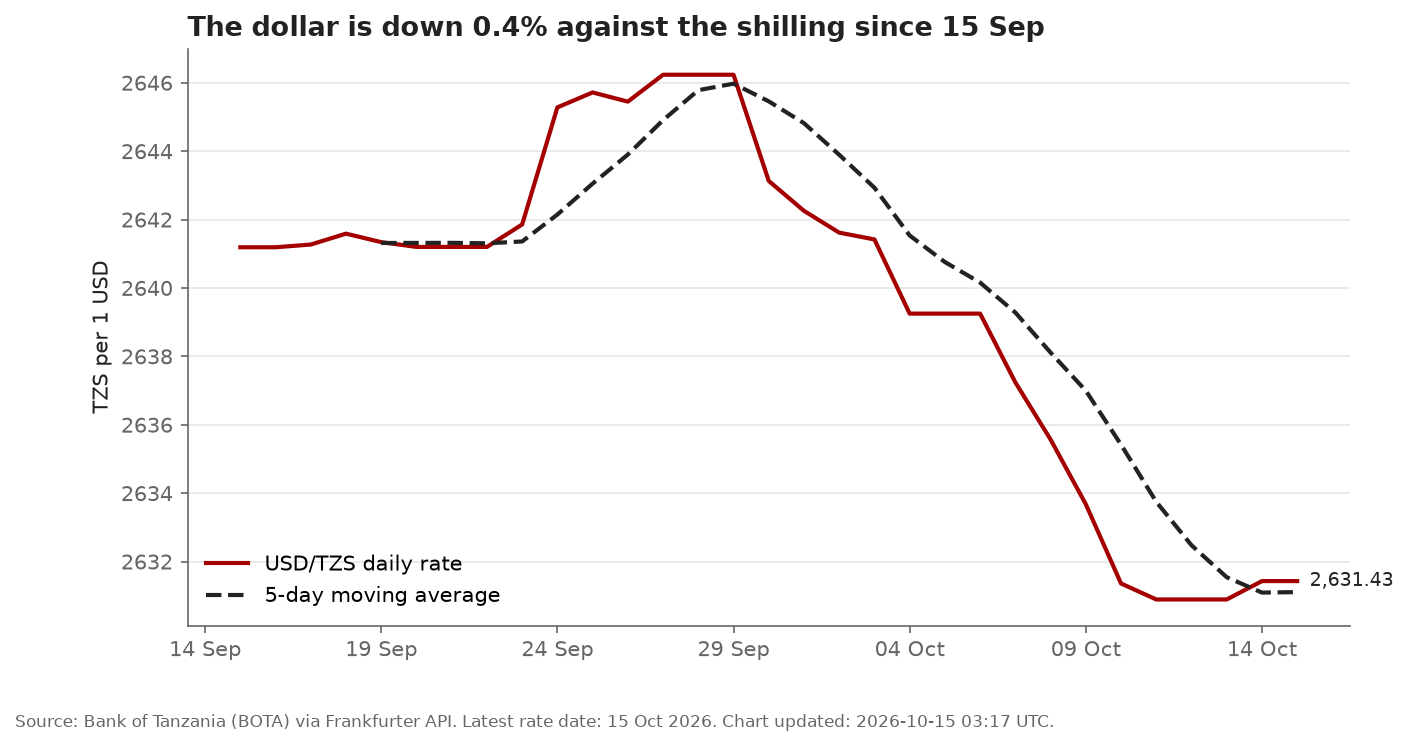

In [28]:
from IPython.display import Image, display


def make_line_chart(df):
    """Line chart of the USD/TZS rate with its 5-day moving average. Returns the saved file path."""
    g = df[df["pair"] == "USD/TZS"].sort_values("date")
    first, last = g.iloc[0], g.iloc[-1]
    change = (last["rate"] - first["rate"]) / first["rate"] * 100
    direction = "down" if change < 0 else "up"
    title = (f"The dollar is {direction} {abs(change):.1f}% against the shilling "
             f"since {first['date'].strftime('%d %b')}")

    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.plot(g["date"], g["rate"], color=HIGHLIGHT, linewidth=2, label="USD/TZS daily rate")
    ax.plot(g["date"], g["ma_short"], color=INK, linewidth=2, linestyle="--",
            label=f"{SHORT_WINDOW}-day moving average")
    ax.annotate(f"{last['rate']:,.2f}", (last["date"], last["rate"]),
                textcoords="offset points", xytext=(6, 0), color=INK, fontsize=9, va="center")

    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK)
    ax.set_ylabel("TZS per 1 USD")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.legend(loc="lower left", frameon=False)
    fig.subplots_adjust(bottom=0.14)
    add_footnote(fig, df)
    return save_chart(fig, "01_usd_tzs_line.png")


line_path = make_line_chart(rates_df)
print("Saved:", line_path.name, f"({line_path.stat().st_size // 1024} KB)")
display(Image(filename=line_path))

Saved: 02_pct_change_bar.png (42 KB)


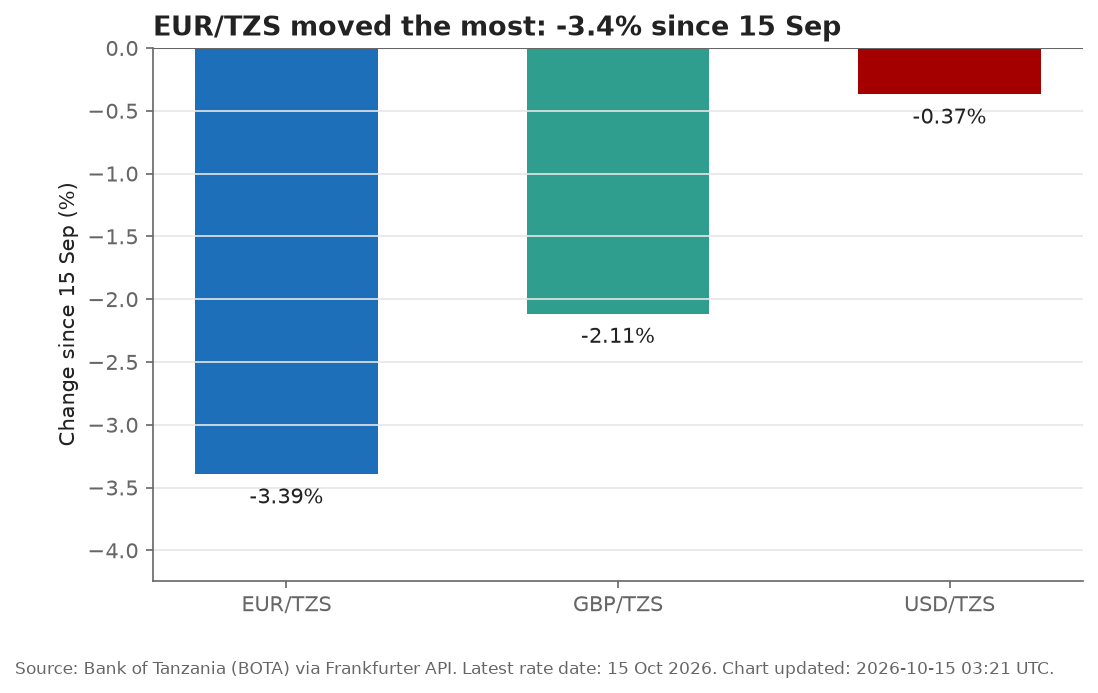

In [29]:
def make_bar_chart(df):
    """Bar chart of the percentage change of each pair since the first day. Returns the saved file path."""
    rows = []
    for pair, g in df.groupby("pair"):
        g = g.sort_values("date")
        change = (g["rate"].iloc[-1] - g["rate"].iloc[0]) / g["rate"].iloc[0] * 100
        rows.append({"pair": pair, "change": change})
    bars = pd.DataFrame(rows).sort_values("change")

    start = df["date"].min().strftime("%d %b")
    top = bars.loc[bars["change"].abs().idxmax()]
    title = f"{top['pair']} moved the most: {top['change']:+.1f}% since {start}"

    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.bar(bars["pair"], bars["change"], color=[PAIR_COLORS[p] for p in bars["pair"]], width=0.55)
    ax.axhline(0, color=MUTED, linewidth=1)
    for i, value in enumerate(bars["change"]):
        ax.annotate(f"{value:+.2f}%", (i, value), textcoords="offset points",
                    xytext=(0, 6 if value >= 0 else -14), ha="center", color=INK, fontsize=10)

    ax.margins(y=0.25)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK)
    ax.set_ylabel(f"Change since {start} (%)")
    fig.subplots_adjust(bottom=0.14)
    add_footnote(fig, df)
    return save_chart(fig, "02_pct_change_bar.png")


bar_path = make_bar_chart(rates_df)
print("Saved:", bar_path.name, f"({bar_path.stat().st_size // 1024} KB)")
display(Image(filename=bar_path))

Saved: 03_correlation_heatmap.png (56 KB)


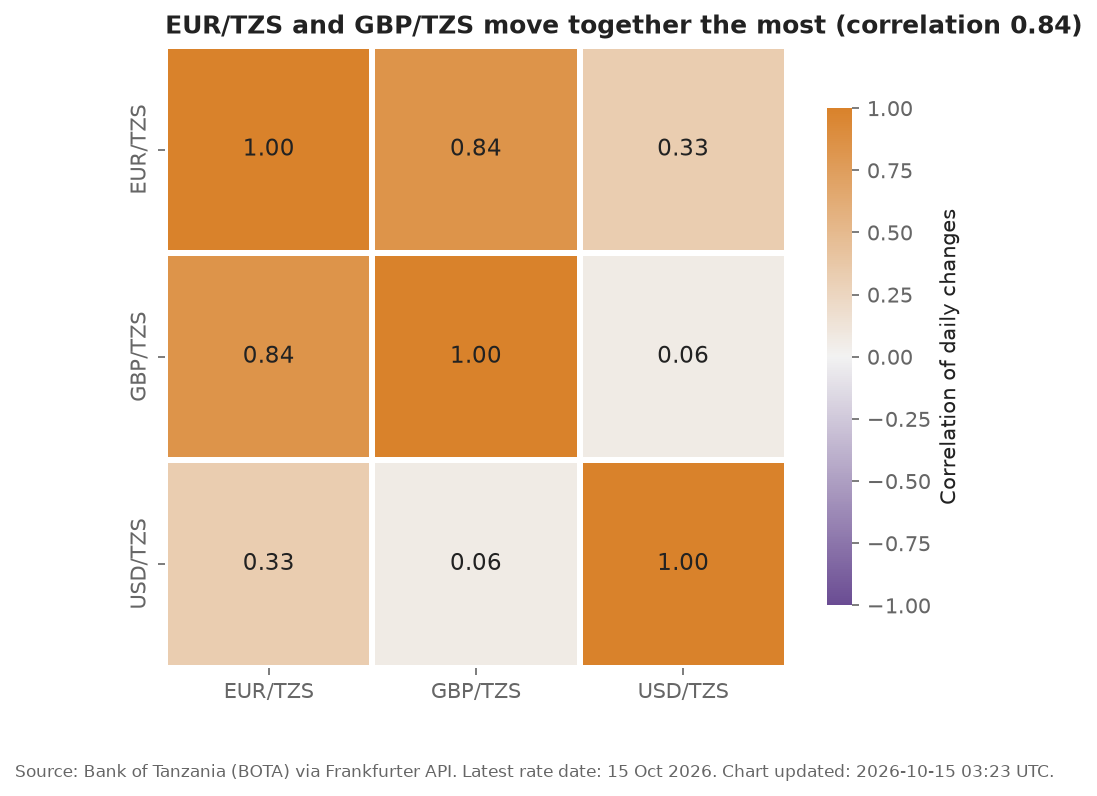

In [30]:
from matplotlib.colors import LinearSegmentedColormap


def make_heatmap(df):
    """Heatmap of the correlation between the daily changes of the pairs. Returns the saved file path."""
    changes = df.pivot(index="date", columns="pair", values="change_pct").dropna()
    corr = changes.corr()
    pairs = list(corr.columns)

    best = None
    for i in range(len(pairs)):
        for j in range(i + 1, len(pairs)):
            value = corr.iloc[i, j]
            if best is None or abs(value) > abs(best[2]):
                best = (pairs[i], pairs[j], value)
    kind = "move together" if best[2] >= 0 else "move in opposite directions"
    title = f"{best[0]} and {best[1]} {kind} the most (correlation {best[2]:.2f})"

    cmap = LinearSegmentedColormap.from_list("diverging", ["#6a4c93", "#f2f2f2", "#d9822b"])
    fig, ax = plt.subplots(figsize=(7, 5.6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1,
                linewidths=2, linecolor="white", square=True, ax=ax,
                annot_kws={"fontsize": 11, "color": INK},
                cbar_kws={"label": "Correlation of daily changes", "shrink": 0.8})
    ax.grid(False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK)
    fig.subplots_adjust(bottom=0.14)
    add_footnote(fig, df)
    return save_chart(fig, "03_correlation_heatmap.png")


heatmap_path = make_heatmap(rates_df)
print("Saved:", heatmap_path.name, f"({heatmap_path.stat().st_size // 1024} KB)")
display(Image(filename=heatmap_path))

Saved: 04_daily_change_histogram.png (53 KB)


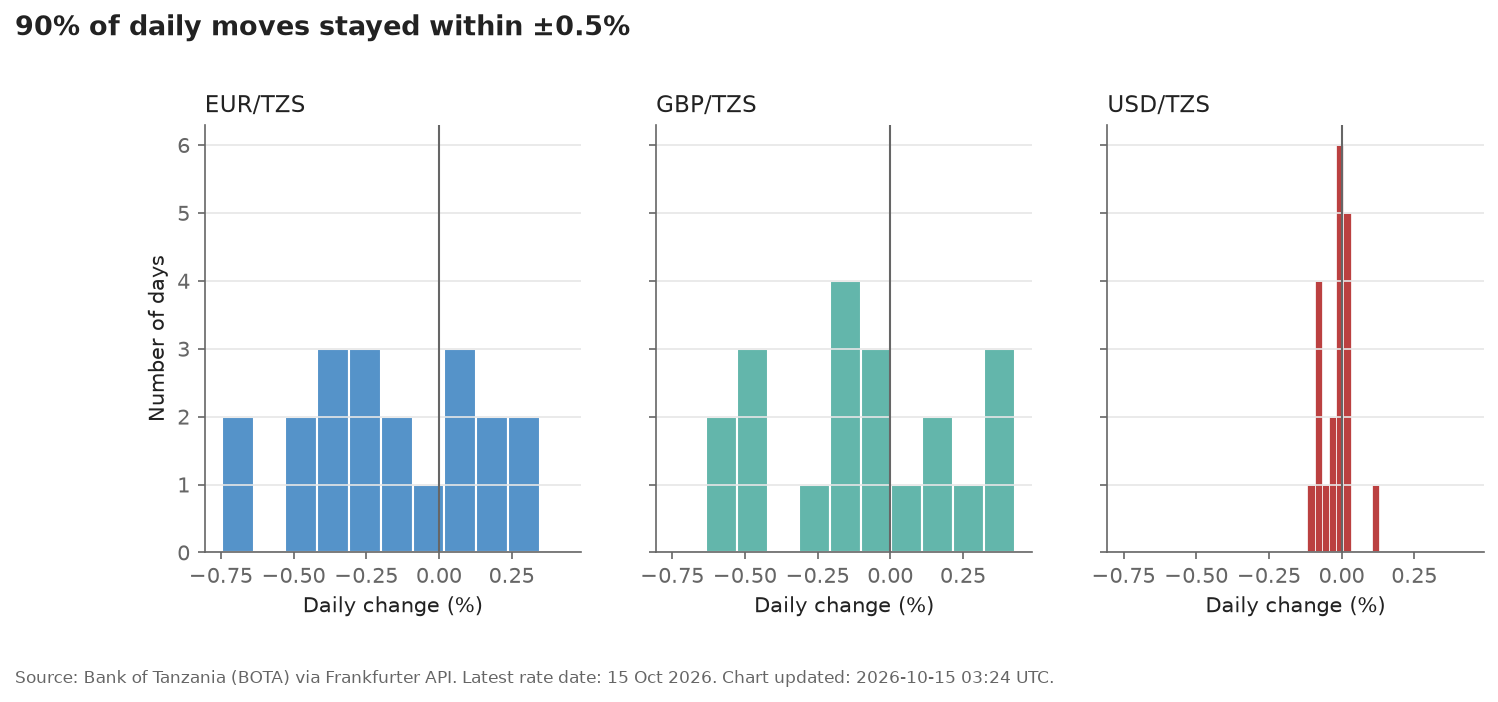

In [31]:
import numpy as np


def make_histogram(df):
    """Histogram of the daily percentage changes, one panel per pair. Returns the saved file path."""
    moves = df[(df["is_repeat"] == 0) & df["change_pct"].notna()]
    share = (moves["change_pct"].abs() <= DAILY_LIMIT).mean() * 100
    title = f"{share:.0f}% of daily moves stayed within ±{DAILY_LIMIT}%"

    pairs = sorted(moves["pair"].unique())
    fig, axes = plt.subplots(1, len(pairs), figsize=(11, 4.6), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, pair in zip(axes, pairs):
        sns.histplot(data=moves[moves["pair"] == pair], x="change_pct", bins=10,
                     color=PAIR_COLORS[pair], edgecolor="white", ax=ax)
        ax.axvline(0, color=MUTED, linewidth=1)
        ax.set_title(pair, loc="left", fontsize=11, color=INK)
        ax.set_xlabel("Daily change (%)")
        ax.set_ylabel("Number of days" if ax is axes[0] else "")

    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.subplots_adjust(top=0.82, bottom=0.2)
    add_footnote(fig, df)
    return save_chart(fig, "04_daily_change_histogram.png")


hist_path = make_histogram(rates_df)
print("Saved:", hist_path.name, f"({hist_path.stat().st_size // 1024} KB)")
display(Image(filename=hist_path))

In [32]:
from PIL import Image as PILImage


def make_charts(df):
    """Create all charts from the rates table and save them in the charts folder.
    Returns the list of saved file paths."""
    paths = [make_line_chart(df), make_bar_chart(df), make_heatmap(df), make_histogram(df)]
    logger.info(f"Charts saved: {len(paths)} files in {CHARTS_DIR.name}/")
    return paths


def run_once():
    """Run one full cycle: fetch, fill missing days, store, check alerts, draw charts and log.
    Returns the list of alerts raised in this run."""
    logger.info("Run started")
    df = fetch_data()
    if df.empty:
        logger.error("Run finished with no data")
        return []
    pairs_fetched = df[["base", "quote"]].drop_duplicates().shape[0]
    rows_changed = save_data(df, conn)
    rates = load_rates()
    alerts = check_alerts(rates, last_n_days=1)
    try:
        make_charts(rates)
    except Exception as error:
        logger.error(f"Charts failed: {type(error).__name__}: {error}")
    logger.info(
        f"Run finished: pairs fetched {pairs_fetched}/{len(PAIRS)}, rows received {len(df)}, "
        f"rows added or updated {rows_changed}, alerts {len(alerts)}"
    )
    return alerts


alerts_now = run_once()

print("Alerts in this run:", len(alerts_now))
print()
for path in sorted(CHARTS_DIR.glob("*.png")):
    with PILImage.open(path) as img:
        print(f"{path.name} | {img.size[0]}x{img.size[1]} px | {round(img.info.get('dpi', (0, 0))[0])} dpi")
print()
print("\n".join(LOG_PATH.read_text(encoding="utf-8").splitlines()[-3:]))

Alerts in this run: 0

01_usd_tzs_line.png | 1408x746 px | 150 dpi
02_pct_change_bar.png | 1098x693 px | 150 dpi
03_correlation_heatmap.png | 1097x796 px | 150 dpi
04_daily_change_histogram.png | 1498x702 px | 150 dpi

2026-10-15 06:25:42,630 | INFO | Filled 1 day(s) with the previous rate for GBP/TZS
2026-10-15 06:25:44,086 | INFO | Charts saved: 4 files in charts/
2026-10-15 06:25:44,086 | INFO | Run finished: pairs fetched 3/3, rows received 90, rows added or updated 0, alerts 0


In [33]:
BACKFILL_DAYS = 190

frames = []
for base, quote in PAIRS:
    records = fetch_history(base, quote, lookback_days=BACKFILL_DAYS)
    if records is None:
        continue
    df = pd.DataFrame(records)
    df["date"] = pd.to_datetime(df["date"])
    df["rate"] = df["rate"].astype(float)
    frames.append(fill_missing_days(df))

backfill_df = pd.concat(frames, ignore_index=True)
rows_changed = save_data(backfill_df, conn)

print("Rows added or updated:", rows_changed)
print(pd.read_sql_query(
    """SELECT base || '/' || quote AS pair, COUNT(*) AS rows_total,
              MIN(date) AS first_date, MAX(date) AS last_date, SUM(is_filled) AS filled
       FROM fx_rates GROUP BY base, quote""", conn))

Rows added or updated: 480
      pair  rows_total  first_date   last_date  filled
0  EUR/TZS         191  2026-04-08  2026-10-15       1
1  GBP/TZS         191  2026-04-08  2026-10-15       1
2  USD/TZS         191  2026-04-08  2026-10-15       1


Saved: 05_monthly_average.png (117 KB)


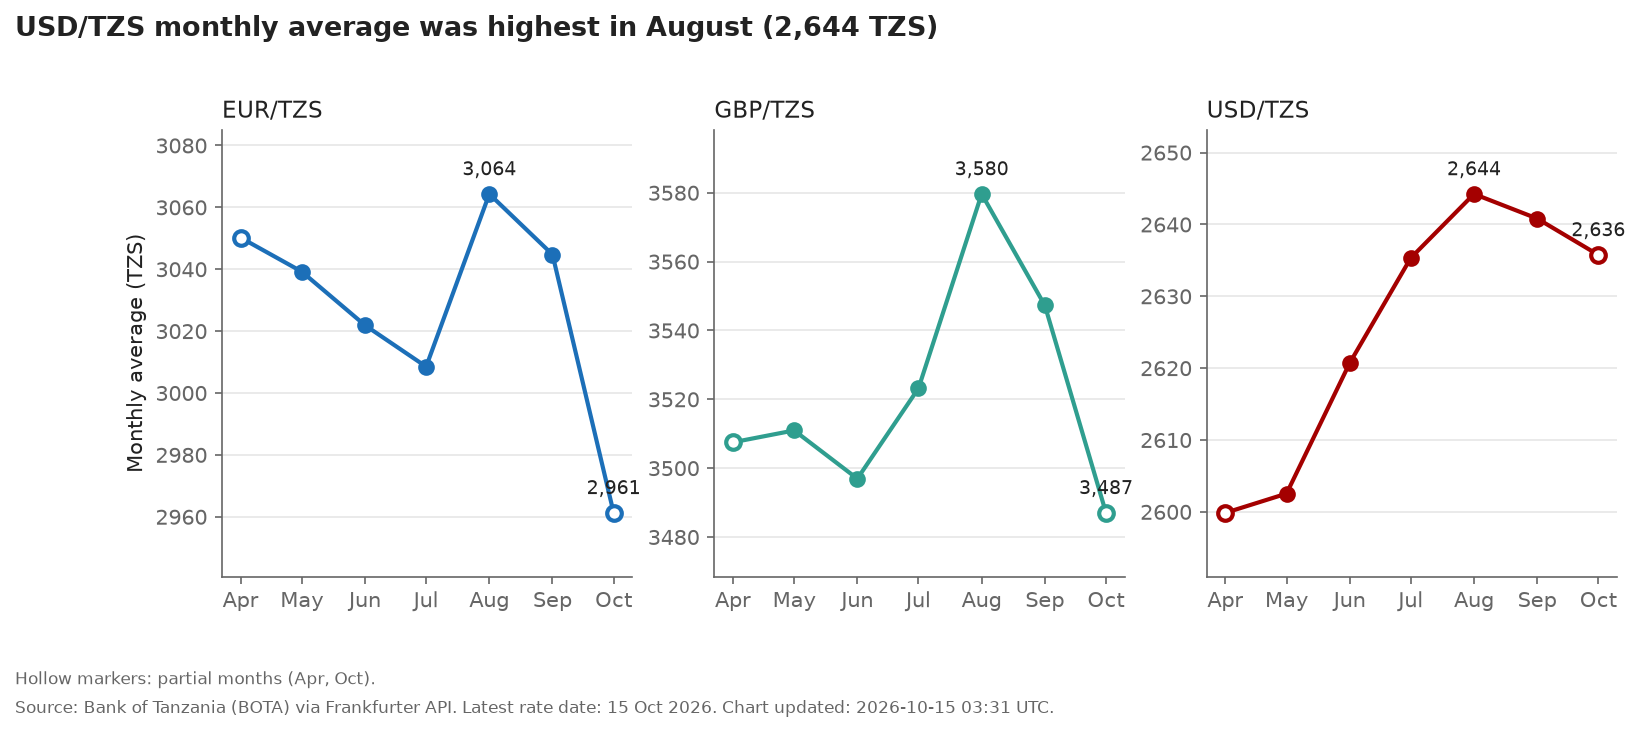

In [34]:
def make_monthly_average_chart(df):
    """Line chart of the monthly average rate, one panel per pair. Partial months are hollow.
    Returns the saved file path."""
    d = df.copy()
    d["month"] = d["date"].dt.to_period("M")
    monthly = d.groupby(["pair", "month"])["rate"].mean().reset_index()
    monthly["month_start"] = monthly["month"].dt.to_timestamp()

    days_per_month = d.groupby("month")["date"].nunique()
    partial = {m for m, n in days_per_month.items() if n < m.days_in_month}

    usd = monthly[monthly["pair"] == "USD/TZS"]
    top = usd.loc[usd["rate"].idxmax()]
    title = f"USD/TZS monthly average was highest in {top['month_start'].strftime('%B')} ({top['rate']:,.0f} TZS)"

    pairs = sorted(monthly["pair"].unique())
    fig, axes = plt.subplots(1, len(pairs), figsize=(12, 4.8), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, pair in zip(axes, pairs):
        g = monthly[monthly["pair"] == pair].reset_index(drop=True)
        color = PAIR_COLORS[pair]
        ax.plot(g["month_start"], g["rate"], color=color, linewidth=2, marker="o", markersize=7)
        part = g[g["month"].isin(partial)]
        ax.plot(part["month_start"], part["rate"], linestyle="", marker="o", markersize=7,
                markerfacecolor="white", markeredgecolor=color, markeredgewidth=2)
        for i in {g["rate"].idxmax(), len(g) - 1}:
            ax.annotate(f"{g.loc[i, 'rate']:,.0f}", (g.loc[i, "month_start"], g.loc[i, "rate"]),
                        textcoords="offset points", xytext=(0, 9), ha="center", color=INK, fontsize=9)
        ax.margins(y=0.2)
        ax.set_title(pair, loc="left", fontsize=11, color=INK)
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        ax.set_ylabel("Monthly average (TZS)" if ax is axes[0] else "")

    note = "Hollow markers: partial months (" + ", ".join(m.strftime("%b") for m in sorted(partial)) + ")."
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.subplots_adjust(top=0.82, bottom=0.2)
    fig.text(0.01, 0.045, note, fontsize=8, color=MUTED, ha="left", va="bottom")
    add_footnote(fig, df)
    return save_chart(fig, "05_monthly_average.png")


monthly_path = make_monthly_average_chart(load_rates())
print("Saved:", monthly_path.name, f"({monthly_path.stat().st_size // 1024} KB)")
display(Image(filename=monthly_path))

Saved: 05_monthly_average.png (74 KB)


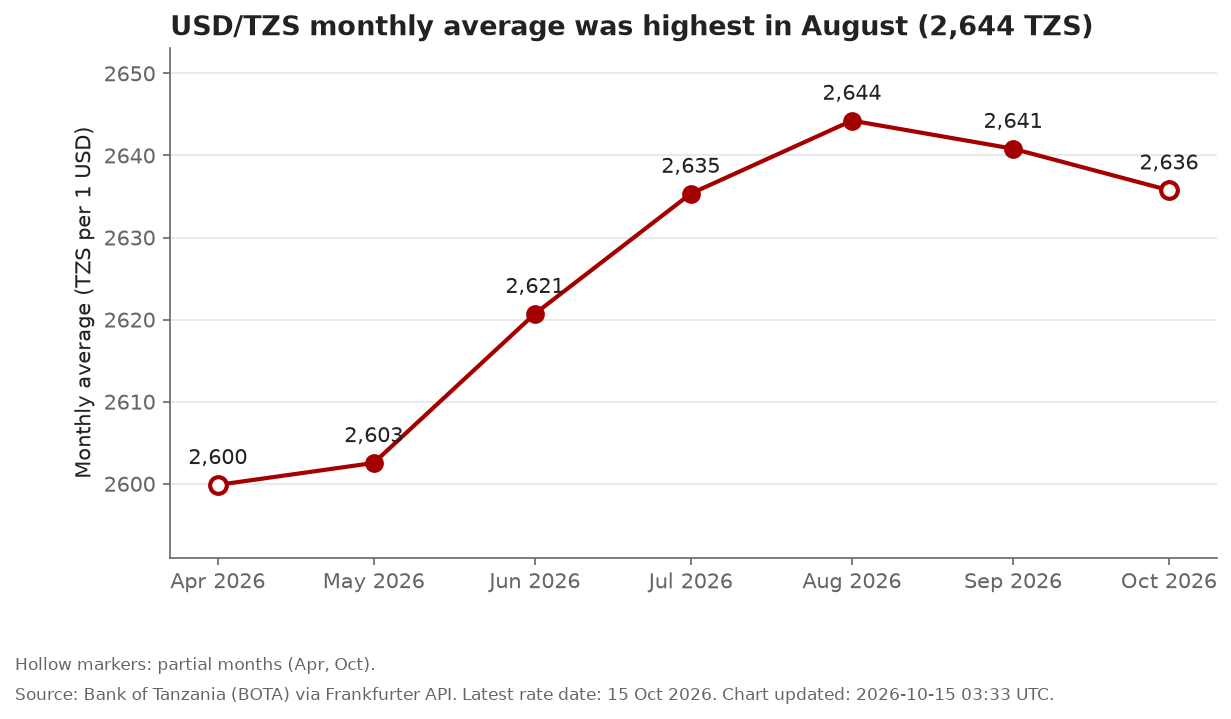

In [35]:
def make_monthly_average_chart(df):
    """Line chart of the USD/TZS monthly average rate. Partial months have hollow markers.
    Returns the saved file path."""
    d = df[df["pair"] == "USD/TZS"].copy()
    d["month"] = d["date"].dt.to_period("M")
    monthly = d.groupby("month")["rate"].mean().reset_index()
    monthly["month_start"] = monthly["month"].dt.to_timestamp()

    days_per_month = d.groupby("month")["date"].nunique()
    partial = {m for m, n in days_per_month.items() if n < m.days_in_month}

    top = monthly.loc[monthly["rate"].idxmax()]
    title = f"USD/TZS monthly average was highest in {top['month_start'].strftime('%B')} ({top['rate']:,.0f} TZS)"

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(monthly["month_start"], monthly["rate"], color=HIGHLIGHT, linewidth=2, marker="o", markersize=8)
    part = monthly[monthly["month"].isin(partial)]
    ax.plot(part["month_start"], part["rate"], linestyle="", marker="o", markersize=8,
            markerfacecolor="white", markeredgecolor=HIGHLIGHT, markeredgewidth=2)
    for _, row in monthly.iterrows():
        ax.annotate(f"{row['rate']:,.0f}", (row["month_start"], row["rate"]),
                    textcoords="offset points", xytext=(0, 10), ha="center", color=INK, fontsize=10)

    ax.margins(y=0.2)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK)
    ax.set_ylabel("Monthly average (TZS per 1 USD)")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    note = "Hollow markers: partial months (" + ", ".join(m.strftime("%b") for m in sorted(partial)) + ")."
    fig.subplots_adjust(bottom=0.2)
    fig.text(0.01, 0.045, note, fontsize=8, color=MUTED, ha="left", va="bottom")
    add_footnote(fig, df)
    return save_chart(fig, "05_monthly_average.png")


monthly_path = make_monthly_average_chart(load_rates())
print("Saved:", monthly_path.name, f"({monthly_path.stat().st_size // 1024} KB)")
display(Image(filename=monthly_path))

In [36]:
with open(PROJECT / "config.json") as f:
    CONFIG = json.load(f)

HISTORY_START = date.fromisoformat(CONFIG["history_start_date"])
lookback = (date.today() - HISTORY_START).days

frames = []
for base, quote in PAIRS:
    records = fetch_history(base, quote, lookback_days=lookback)
    if records is None:
        continue
    df = pd.DataFrame(records)
    df["date"] = pd.to_datetime(df["date"])
    df["rate"] = df["rate"].astype(float)
    frames.append(fill_missing_days(df))

backfill_df = pd.concat(frames, ignore_index=True)
rows_changed = save_data(backfill_df, conn)

print("Start date:", HISTORY_START, "| Days requested:", lookback)
print("Rows added or updated:", rows_changed)
print(pd.read_sql_query(
    """SELECT base || '/' || quote AS pair, COUNT(*) AS rows_total,
              MIN(date) AS first_date, MAX(date) AS last_date, SUM(is_filled) AS filled
       FROM fx_rates GROUP BY base, quote""", conn))

Start date: 2026-01-01 | Days requested: 287
Rows added or updated: 291
      pair  rows_total  first_date   last_date  filled
0  EUR/TZS         288  2026-01-01  2026-10-15       1
1  GBP/TZS         288  2026-01-01  2026-10-15       1
2  USD/TZS         288  2026-01-01  2026-10-15       1


Saved: 05_monthly_average.png (76 KB)


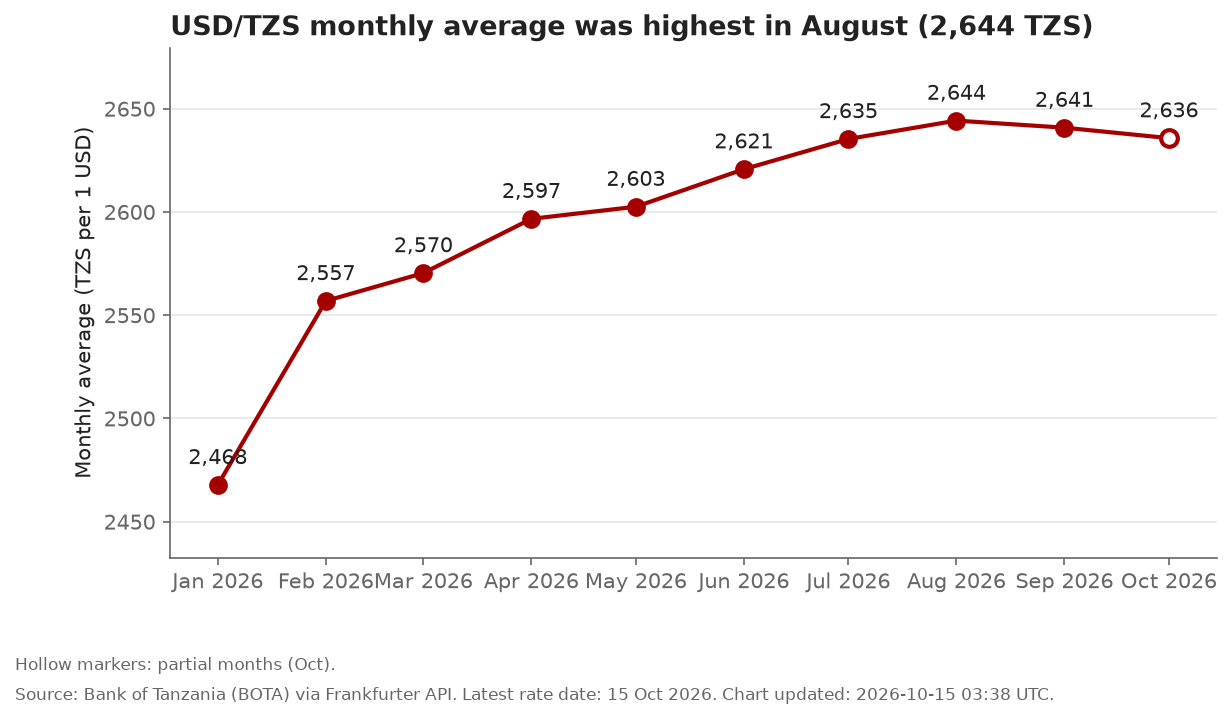

In [37]:
monthly_path = make_monthly_average_chart(load_rates())
print("Saved:", monthly_path.name, f"({monthly_path.stat().st_size // 1024} KB)")
display(Image(filename=monthly_path))

Saved: 06_current_month_daily.png (71 KB)


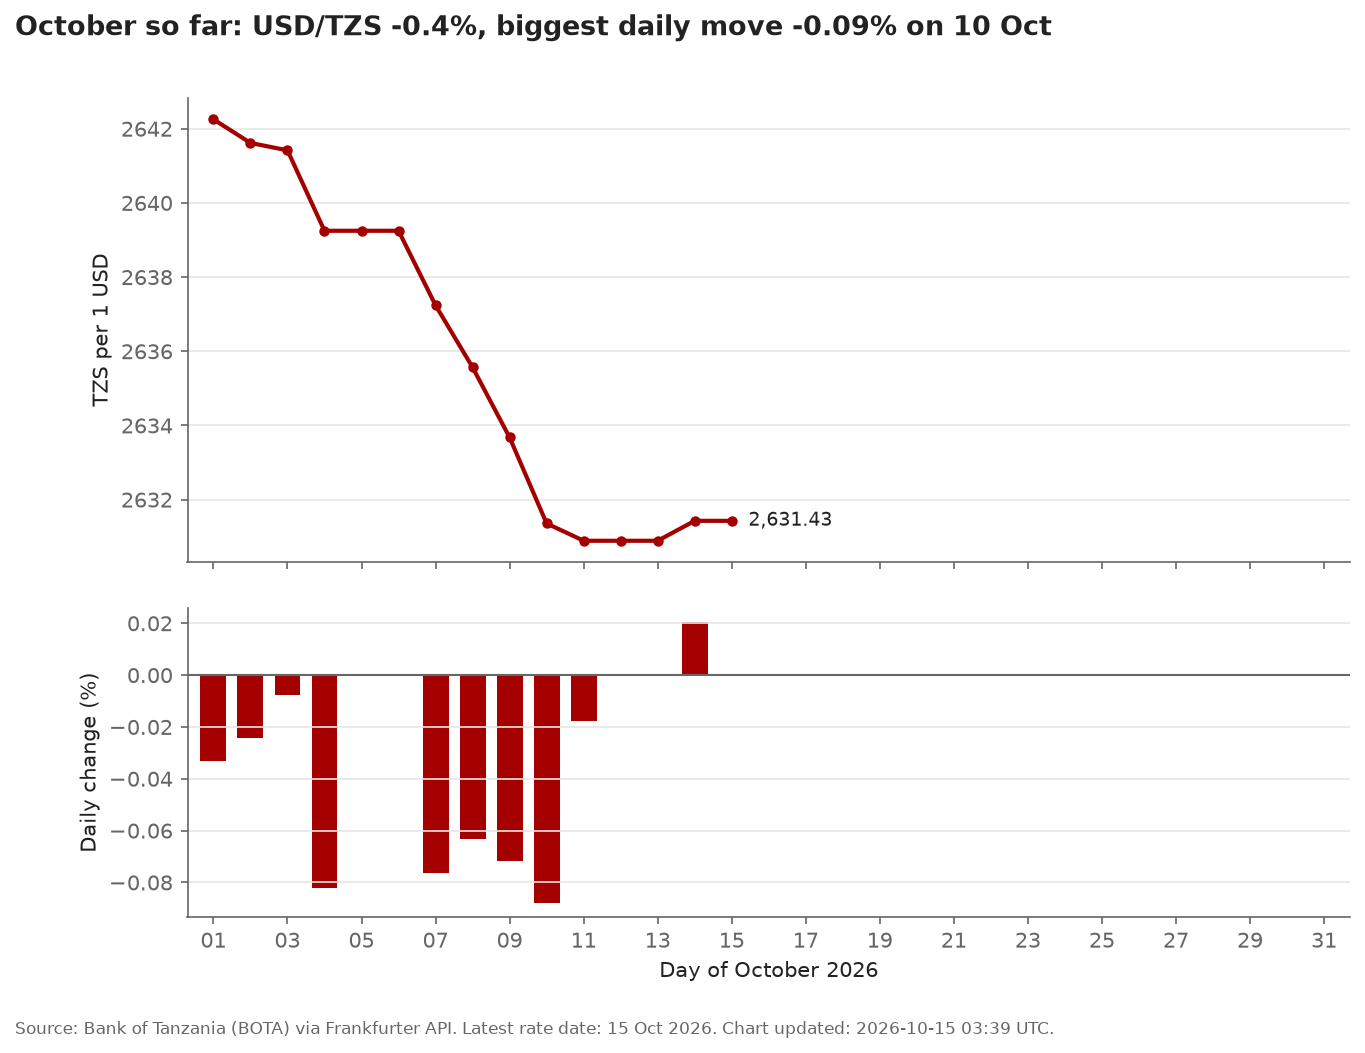

In [38]:
def make_month_daily_chart(df):
    """Two-panel chart for the current month: daily USD/TZS rate (top) and daily change in % (bottom).
    Returns the saved file path."""
    today = pd.Timestamp(date.today())
    month_start = today.replace(day=1)
    month_end = month_start + pd.offsets.MonthEnd(0)
    month_name = today.strftime("%B")

    g = df[(df["pair"] == "USD/TZS") & (df["date"] >= month_start) & (df["date"] <= month_end)]
    g = g.sort_values("date").reset_index(drop=True)
    moves = g["change_pct"].fillna(0)

    total = (g["rate"].iloc[-1] - g["rate"].iloc[0]) / g["rate"].iloc[0] * 100
    big = moves.abs().idxmax()
    title = (f"{month_name} so far: USD/TZS {total:+.1f}%, biggest daily move "
             f"{moves[big]:+.2f}% on {g['date'][big].strftime('%d %b')}")

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 2]})
    ax1.plot(g["date"], g["rate"], color=HIGHLIGHT, linewidth=2, marker="o", markersize=4)
    ax1.annotate(f"{g['rate'].iloc[-1]:,.2f}", (g["date"].iloc[-1], g["rate"].iloc[-1]),
                 textcoords="offset points", xytext=(8, 0), color=INK, fontsize=9, va="center")
    ax1.set_ylabel("TZS per 1 USD")

    ax2.bar(g["date"], moves, color=HIGHLIGHT, width=0.7)
    ax2.axhline(0, color=MUTED, linewidth=1)
    ax2.set_ylabel("Daily change (%)")
    ax2.set_xlabel(f"Day of {month_name} {today.year}")
    ax2.set_xlim(month_start - pd.Timedelta(days=0.7), month_end + pd.Timedelta(days=0.7))
    ax2.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d"))

    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.subplots_adjust(top=0.9, bottom=0.12, hspace=0.12)
    add_footnote(fig, df)
    return save_chart(fig, "06_current_month_daily.png")


month_path = make_month_daily_chart(load_rates())
print("Saved:", month_path.name, f"({month_path.stat().st_size // 1024} KB)")
display(Image(filename=month_path))

Saved: 07_usd_tzs_trend.png (72 KB)


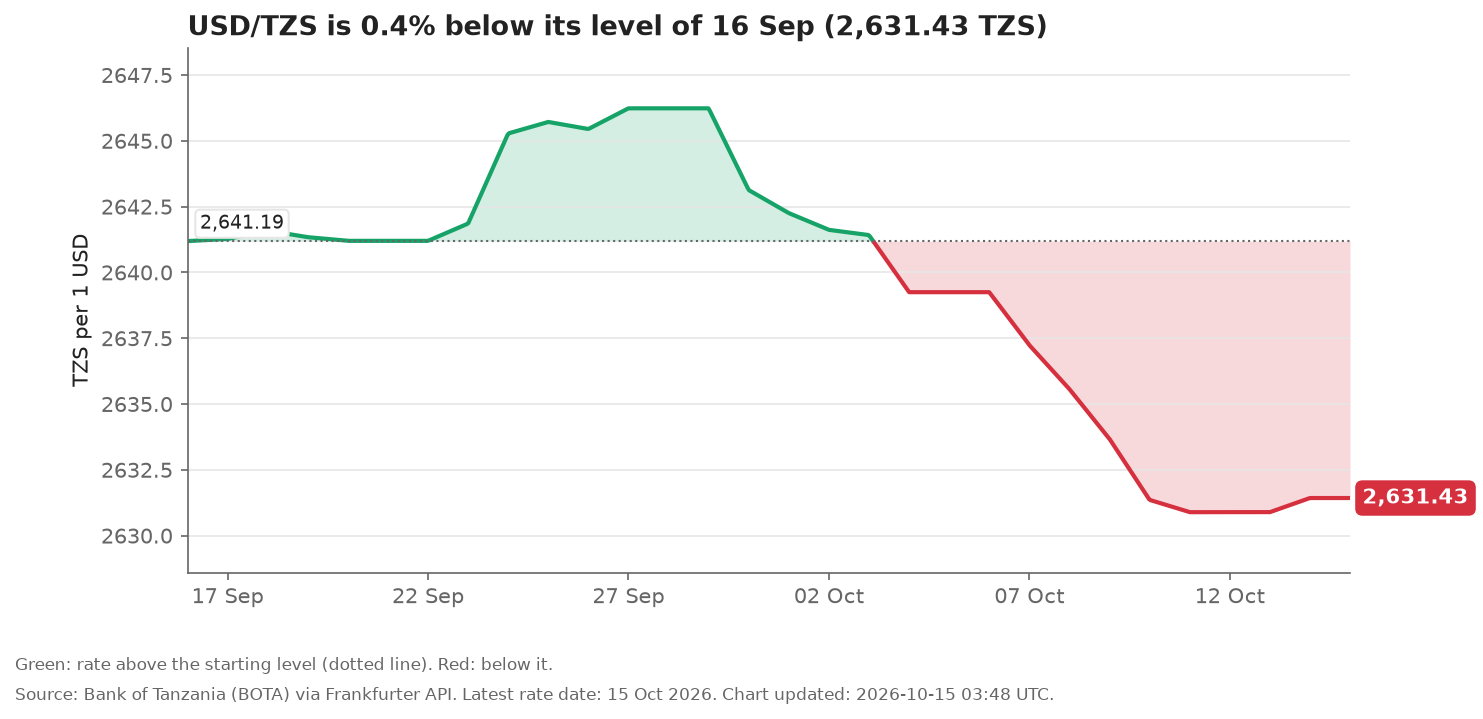

In [39]:
GOOD, BAD = "#16a368", "#d6303f"


def make_trend_chart(df):
    """Daily trend chart of USD/TZS for the last 30 days. The area is green above the starting rate
    and red below it. Returns the saved file path."""
    g = df[df["pair"] == "USD/TZS"].sort_values("date").tail(HISTORY_DAYS)
    ref, last = g["rate"].iloc[0], g["rate"].iloc[-1]
    change = (last - ref) / ref * 100
    colour = GOOD if last >= ref else BAD
    where = "above" if change >= 0 else "below"
    title = (f"USD/TZS is {abs(change):.1f}% {where} its level of "
             f"{g['date'].iloc[0].strftime('%d %b')} ({last:,.2f} TZS)")

    x = mdates.date2num(g["date"])
    xs = np.linspace(x.min(), x.max(), 800)
    ys = np.interp(xs, x, g["rate"])
    up = ys >= ref

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.fill_between(xs, ys, ref, where=up, interpolate=True, color=GOOD, alpha=0.18, linewidth=0)
    ax.fill_between(xs, ys, ref, where=~up, interpolate=True, color=BAD, alpha=0.18, linewidth=0)
    ax.plot(xs, np.where(up, ys, np.nan), color=GOOD, linewidth=2)
    ax.plot(xs, np.where(~up, ys, np.nan), color=BAD, linewidth=2)
    ax.axhline(ref, color=MUTED, linewidth=1, linestyle=":")

    ax.annotate(f"{ref:,.2f}", xy=(0, ref), xycoords=("axes fraction", "data"),
                xytext=(6, 6), textcoords="offset points", fontsize=9, color=INK,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=GRID))
    ax.annotate(f"{last:,.2f}", xy=(1, last), xycoords=("axes fraction", "data"),
                xytext=(6, 0), textcoords="offset points", va="center", ha="left",
                fontsize=10, fontweight="bold", color="white", annotation_clip=False,
                bbox=dict(boxstyle="round,pad=0.3", fc=colour, ec=colour))

    span = ys.max() - ys.min()
    ax.set_ylim(ys.min() - span * 0.15, ys.max() + span * 0.15)
    ax.set_xlim(xs.min(), xs.max())
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.set_ylabel("TZS per 1 USD")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK)

    fig.subplots_adjust(bottom=0.18, right=0.9)
    fig.text(0.01, 0.045, "Green: rate above the starting level (dotted line). Red: below it.",
             fontsize=8, color=MUTED, ha="left", va="bottom")
    add_footnote(fig, df)
    return save_chart(fig, "07_usd_tzs_trend.png")


trend_path = make_trend_chart(load_rates())
print("Saved:", trend_path.name, f"({trend_path.stat().st_size // 1024} KB)")
display(Image(filename=trend_path))

Saved: 07_usd_tzs_trend.png and 08_usd_tzs_year_trend.png


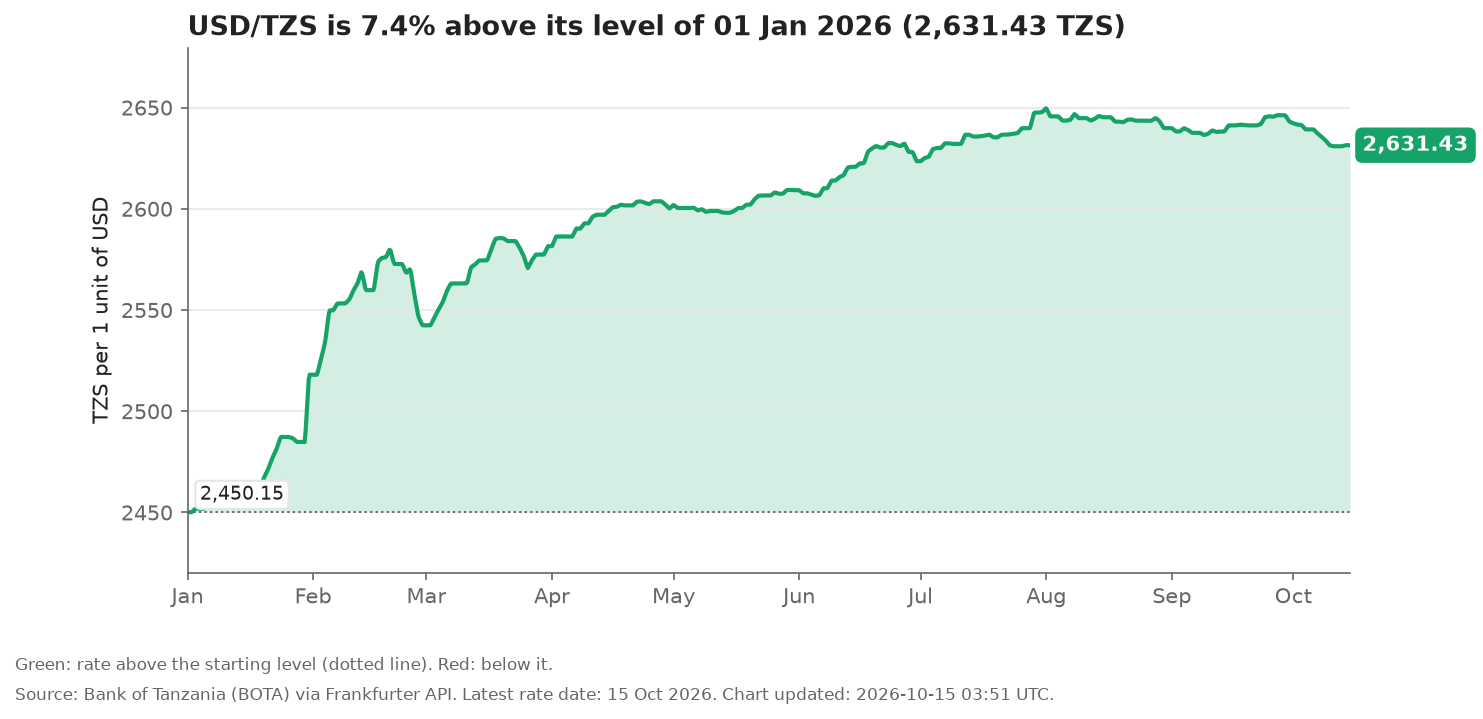

In [40]:
GOOD, BAD = "#16a368", "#d6303f"


def make_trend_chart(df, start=None, filename="07_usd_tzs_trend.png", pair="USD/TZS"):
    """Daily trend chart for one pair. The area is green above the starting rate and red below it.
    Uses the last 30 days, or all days from the start date when it is given. Returns the saved file path."""
    g = df[df["pair"] == pair].sort_values("date")
    g = g[g["date"] >= pd.Timestamp(start)] if start else g.tail(HISTORY_DAYS)
    ref, last = g["rate"].iloc[0], g["rate"].iloc[-1]
    change = (last - ref) / ref * 100
    colour = GOOD if last >= ref else BAD
    where = "above" if change >= 0 else "below"
    title = (f"{pair} is {abs(change):.1f}% {where} its level of "
             f"{g['date'].iloc[0].strftime('%d %b %Y')} ({last:,.2f} TZS)")

    x = mdates.date2num(g["date"])
    xs = np.linspace(x.min(), x.max(), max(800, len(g) * 4))
    ys = np.interp(xs, x, g["rate"])
    up = ys >= ref

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.fill_between(xs, ys, ref, where=up, interpolate=True, color=GOOD, alpha=0.18, linewidth=0)
    ax.fill_between(xs, ys, ref, where=~up, interpolate=True, color=BAD, alpha=0.18, linewidth=0)
    ax.plot(xs, np.where(up, ys, np.nan), color=GOOD, linewidth=2)
    ax.plot(xs, np.where(~up, ys, np.nan), color=BAD, linewidth=2)
    ax.axhline(ref, color=MUTED, linewidth=1, linestyle=":")

    ax.annotate(f"{ref:,.2f}", xy=(0, ref), xycoords=("axes fraction", "data"),
                xytext=(6, 6), textcoords="offset points", fontsize=9, color=INK,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=GRID))
    ax.annotate(f"{last:,.2f}", xy=(1, last), xycoords=("axes fraction", "data"),
                xytext=(6, 0), textcoords="offset points", va="center", ha="left",
                fontsize=10, fontweight="bold", color="white", annotation_clip=False,
                bbox=dict(boxstyle="round,pad=0.3", fc=colour, ec=colour))

    span = ys.max() - ys.min()
    ax.set_ylim(ys.min() - span * 0.15, ys.max() + span * 0.15)
    ax.set_xlim(xs.min(), xs.max())
    ax.xaxis_date()
    if len(g) > 90:
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    else:
        ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.set_ylabel("TZS per 1 unit of " + pair.split("/")[0])
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK)

    fig.subplots_adjust(bottom=0.18, right=0.9)
    fig.text(0.01, 0.045, "Green: rate above the starting level (dotted line). Red: below it.",
             fontsize=8, color=MUTED, ha="left", va="bottom")
    add_footnote(fig, df)
    return save_chart(fig, filename)


rates = load_rates()
trend_path = make_trend_chart(rates)
year_path = make_trend_chart(rates, start=HISTORY_START, filename="08_usd_tzs_year_trend.png")

print("Saved:", trend_path.name, "and", year_path.name)
display(Image(filename=year_path))

In [41]:
def make_charts(df):
    """Create all 8 charts and save them in the charts folder. Charts 1 to 4 use the last 30 days,
    charts 5 to 8 use the longer history. Returns the list of saved file paths."""
    recent = df[df["date"] >= df["date"].max() - pd.Timedelta(days=HISTORY_DAYS - 1)]
    paths = [
        make_line_chart(recent),
        make_bar_chart(recent),
        make_heatmap(recent),
        make_histogram(recent),
        make_monthly_average_chart(df),
        make_month_daily_chart(df),
        make_trend_chart(df),
        make_trend_chart(df, start=HISTORY_START, filename="08_usd_tzs_year_trend.png"),
    ]
    logger.info(f"Charts saved: {len(paths)} files in {CHARTS_DIR.name}/")
    return paths


alerts_now = run_once()

print("Alerts in this run:", len(alerts_now))
print()
for path in sorted(CHARTS_DIR.glob("*.png")):
    with PILImage.open(path) as img:
        print(f"{path.name} | {img.size[0]}x{img.size[1]} px | {round(img.info.get('dpi', (0, 0))[0])} dpi")
print()
print("\n".join(LOG_PATH.read_text(encoding="utf-8").splitlines()[-3:]))

Alerts in this run: 0

01_usd_tzs_line.png | 1408x746 px | 150 dpi
02_pct_change_bar.png | 1098x693 px | 150 dpi
03_correlation_heatmap.png | 1097x796 px | 150 dpi
04_daily_change_histogram.png | 1498x702 px | 150 dpi
05_monthly_average.png | 1231x719 px | 150 dpi
06_current_month_daily.png | 1365x1053 px | 150 dpi
07_usd_tzs_trend.png | 1483x719 px | 150 dpi
08_usd_tzs_year_trend.png | 1483x719 px | 150 dpi

2026-10-15 06:52:33,528 | INFO | Filled 1 day(s) with the previous rate for GBP/TZS
2026-10-15 06:52:36,508 | INFO | Charts saved: 8 files in charts/
2026-10-15 06:52:36,509 | INFO | Run finished: pairs fetched 3/3, rows received 90, rows added or updated 0, alerts 0


In [42]:
def build_summary(conn):
    """Return one row per pair with the latest rate, the change since the previous day,
    and the minimum, maximum and average rate of the last 30 days."""
    rows = pd.read_sql_query(
        "SELECT date, base, quote, rate, prev_rate, change_pct, is_filled FROM fx_rates_clean", conn)
    rows["pair"] = rows["base"] + "/" + rows["quote"]
    latest = rows.sort_values("date").groupby("pair").tail(1).set_index("pair")

    stats = pd.read_sql_query(
        """SELECT base || '/' || quote AS pair,
                  MIN(rate) AS min_rate, MAX(rate) AS max_rate, AVG(rate) AS avg_rate
           FROM fx_rates_clean
           WHERE date >= date((SELECT MAX(date) FROM fx_rates_clean), ?)
           GROUP BY base, quote""",
        conn, params=(f"-{HISTORY_DAYS - 1} days",),
    ).set_index("pair")

    summary = latest[["date", "rate", "prev_rate", "change_pct", "is_filled"]].join(stats)
    summary = summary.rename(columns={"rate": "latest_rate"})
    summary["change_abs"] = summary["latest_rate"] - summary["prev_rate"]
    return summary


summary_df = build_summary(conn)
print(summary_df.round(4).to_string())

               date  latest_rate  prev_rate  change_pct  is_filled   min_rate   max_rate   avg_rate  change_abs
pair                                                                                                           
GBP/TZS  2026-10-15    3482.9585  3482.9585         0.0          1  3476.1904  3562.5441  3506.8527         0.0
EUR/TZS  2026-10-15    2941.9369  2941.9369         0.0          1  2941.9369  3048.8172  2994.2897         0.0
USD/TZS  2026-10-15    2631.4283  2631.4283         0.0          1  2630.8910  2646.2347  2639.5177         0.0


In [43]:
alerts_df = check_alerts(load_rates(), last_n_days=1)
print(type(alerts_df))
print(alerts_df)

<class 'list'>
[]


In [44]:
import base64

def image_to_html(path, alt):
    """Read a PNG file and return an <img> tag with the picture embedded in the HTML itself."""
    encoded = base64.b64encode(Path(path).read_bytes()).decode("ascii")
    return f'<img src="data:image/png;base64,{encoded}" alt="{alt}" style="max-width:100%;height:auto;">'


test_tag = image_to_html(CHARTS_DIR / "01_usd_tzs_line.png", "USD/TZS line chart")
print(len(test_tag), "characters")
print(test_tag[:80])

113099 characters
<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAABYAAAALqCAYAAACMmfCcAAAA


In [45]:
from datetime import datetime, timezone
from html import escape

REPORTS_DIR = PROJECT / CONFIG["folders"]["reports"]

CHART_FILES = [
    ("07_usd_tzs_trend.png",         "USD/TZS daily trend, last 30 days"),
    ("08_usd_tzs_year_trend.png",    "USD/TZS daily trend, 2026 to date"),
    ("01_usd_tzs_line.png",          "All pairs, last 30 days"),
    ("02_pct_change_bar.png",        "Percentage change by pair"),
    ("05_monthly_average.png",       "USD/TZS monthly average"),
    ("06_current_month_daily.png",   "Current month, daily rate and change"),
    ("03_correlation_heatmap.png",   "Correlation between pairs"),
    ("04_daily_change_histogram.png", "Distribution of daily changes"),
]


def build_report(summary, alerts):
    """Build the HTML dashboard, save it in Reports/, and return its path."""
    now_utc = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

    rows_html = ""
    for pair, r in summary.iterrows():
        note = " (carried forward)" if r["is_filled"] == 1 else ""
        rows_html += (
            f"<tr><td>{escape(pair)}</td>"
            f"<td>{r['latest_rate']:,.2f}{note}</td>"
            f"<td>{r['change_abs']:+,.2f} ({r['change_pct']:+.2f}%)</td>"
            f"<td>{r['min_rate']:,.2f}</td><td>{r['max_rate']:,.2f}</td>"
            f"<td>{r['avg_rate']:,.2f}</td><td>{escape(str(r['date']))}</td></tr>"
        )

    if alerts:
        items = "".join(f"<li>{escape(str(a))}</li>" for a in alerts)
        alerts_html = f"<ul>{items}</ul>"
    else:
        alerts_html = "<p>No alerts today.</p>"

    charts_html = ""
    for filename, alt in CHART_FILES:
        path = CHARTS_DIR / filename
        if path.exists():
            charts_html += f"<h3>{escape(alt)}</h3>{image_to_html(path, alt)}"

    html = f"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>FX Daily Report</title>
<style>
body{{font-family:Arial,sans-serif;color:#222;max-width:900px;margin:0 auto;padding:16px}}
h1{{color:#a40000;margin-bottom:0}} .sub{{color:#666;margin-top:4px}}
table{{border-collapse:collapse;width:100%;font-size:14px}}
th,td{{border:1px solid #ddd;padding:8px;text-align:right}}
th{{background:#f3f3f3}} td:first-child,th:first-child{{text-align:left}}
</style></head><body>
<h1>FX Daily Report: Bank of Tanzania rates</h1>
<p class="sub">Source: Bank of Tanzania via Frankfurter API. Generated {now_utc}.</p>
<h2>Latest rates (min, max, average over the last {HISTORY_DAYS} days)</h2>
<table><tr><th>Pair</th><th>Latest (TZS)</th><th>Change vs previous day</th>
<th>Min</th><th>Max</th><th>Average</th><th>Rate date</th></tr>{rows_html}</table>
<h2>Alerts</h2>{alerts_html}
<h2>Charts</h2>{charts_html}
</body></html>"""

    REPORTS_DIR.mkdir(exist_ok=True)
    out = REPORTS_DIR / "fx_report.html"
    out.write_text(html, encoding="utf-8")
    logger.info(f"Report saved: {out.name} ({out.stat().st_size // 1024} KB)")
    return out


report_path = build_report(build_summary(conn), alerts_df)
print(report_path)

c:\Users\laize\OneDrive\Famola\Training\Python For Banking & Finance Analytics with AI\BOT_Live_Data_Assignment\Reports\fx_report.html


In [46]:
def run_once():
    logger.info("Run started")
    df = fetch_data()
    if df.empty:
        logger.error("Run finished with no data")
        return []
    pairs_fetched = df[["base", "quote"]].drop_duplicates().shape[0]
    rows_changed = save_data(df, conn)
    rates = load_rates()
    alerts = check_alerts(rates, last_n_days=1)
    try:
        make_charts(rates)
    except Exception as error:
        logger.error(f"Charts failed: {type(error).__name__}: {error}")
    try:
        build_report(build_summary(conn), alerts)
    except Exception as error:
        logger.error(f"Report failed: {type(error).__name__}: {error}")
    logger.info(f"Run finished: pairs fetched {pairs_fetched}/{len(PAIRS)}, rows received {len(df)}, rows added or updated {rows_changed}, alerts {len(alerts)}")
    return alerts


run_once()

[]

In [ ]:
#Check that the notebook can read .env data
import os
from dotenv import load_dotenv

load_dotenv(PROJECT / ".env", override=True)

for key in ["EMAIL_SENDER", "EMAIL_APP_PASSWORD", "EMAIL_RECEIVER", "SMTP_SERVER", "SMTP_PORT"]:
    value = os.getenv(key)
    if value is None:
        print(f"{key}: MISSING")
    elif key == "EMAIL_APP_PASSWORD":
        print(f"{key}: found, {len(value)} characters")
    else:
        print(f"{key}: {value}")

EMAIL_SENDER: excelninjatz@gmail.com
EMAIL_APP_PASSWORD: found, 16 characters
EMAIL_RECEIVER: excelninjatz@gmail.com
SMTP_SERVER: smtp.gmail.com
SMTP_PORT: 587


In [48]:
#Write the email function and send a test

import smtplib
from email.message import EmailMessage


def send_report_email(report_path, summary, alerts):
    """Email a short summary with the HTML report attached. Returns True if sent."""
    sender = os.getenv("EMAIL_SENDER")
    password = os.getenv("EMAIL_APP_PASSWORD")
    receiver = os.getenv("EMAIL_RECEIVER")
    server = os.getenv("SMTP_SERVER")
    port = int(os.getenv("SMTP_PORT", "587"))

    if not all([sender, password, receiver, server]):
        logger.error("Email not sent: missing email settings in .env")
        return False

    lines = []
    for pair, r in summary.iterrows():
        note = " (carried forward)" if r["is_filled"] == 1 else ""
        lines.append(f"{pair}: {r['latest_rate']:,.2f}{note}, change {r['change_pct']:+.2f}%")
    alert_text = "\n".join(f"- {a}" for a in alerts) if alerts else "No alerts today."
    report_date = summary["date"].max()

    body = (
        f"FX Daily Report: Bank of Tanzania rates ({report_date})\n\n"
        + "\n".join(lines)
        + f"\n\nAlerts:\n{alert_text}\n\nThe full dashboard with charts is attached (open it in a browser)."
    )

    msg = EmailMessage()
    msg["Subject"] = f"FX Daily Report {report_date}"
    msg["From"] = sender
    msg["To"] = receiver
    msg.set_content(body)
    msg.add_attachment(
        Path(report_path).read_bytes(),
        maintype="text", subtype="html", filename=Path(report_path).name,
    )

    try:
        with smtplib.SMTP(server, port, timeout=30) as smtp:
            smtp.starttls()
            smtp.login(sender, password)
            smtp.send_message(msg)
        logger.info(f"Email sent to {receiver} with {Path(report_path).name} attached")
        return True
    except Exception as error:
        logger.error(f"Email failed: {type(error).__name__}: {error}")
        return False


sent = send_report_email(REPORTS_DIR / "fx_report.html", build_summary(conn), alerts_df)
print("Email sent:", sent)

Email sent: True


In [50]:
# open the report in PDF insted of HTML
#Install reportlab

%pip install reportlab

  Using cached reportlab-5.0.1-py3-none-any.whl.metadata (1.6 kB)
Using cached reportlab-5.0.1-py3-none-any.whl (2.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.lib.utils import ImageReader
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer,
                                Table, TableStyle, Image, KeepTogether)


def build_pdf_report(summary, alerts):
    """Build the PDF report in Reports/ and return its path."""
    now_utc = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    out = REPORTS_DIR / "fx_report.pdf"
    REPORTS_DIR.mkdir(exist_ok=True)

    styles = getSampleStyleSheet()
    title_style = ParagraphStyle("title", parent=styles["Title"], alignment=0,
                                 textColor=colors.HexColor("#a40000"), fontSize=18)
    small = ParagraphStyle("small", parent=styles["Normal"], fontSize=8,
                           textColor=colors.HexColor("#666666"))

    doc = SimpleDocTemplate(str(out), pagesize=A4, title="FX Daily Report",
                            leftMargin=15 * mm, rightMargin=15 * mm,
                            topMargin=15 * mm, bottomMargin=15 * mm)

    story = [
        Paragraph("FX Daily Report: Bank of Tanzania rates", title_style),
        Paragraph(f"Source: Bank of Tanzania via Frankfurter API. Generated {now_utc}.", small),
        Spacer(1, 8),
        Paragraph(f"Latest rates (min, max, average over the last {HISTORY_DAYS} days)", styles["Heading2"]),
    ]

    data = [["Pair", "Latest (TZS)", "Change vs previous day", "Min", "Max", "Average", "Rate date"]]
    has_filled = False
    for pair, r in summary.iterrows():
        mark = "*" if r["is_filled"] == 1 else ""
        has_filled = has_filled or bool(mark)
        data.append([
            pair, f"{r['latest_rate']:,.2f}{mark}",
            f"{r['change_abs']:+,.2f} ({r['change_pct']:+.2f}%)",
            f"{r['min_rate']:,.2f}", f"{r['max_rate']:,.2f}",
            f"{r['avg_rate']:,.2f}", str(r["date"]),
        ])
    table = Table(data, repeatRows=1)
    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#f3f3f3")),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.HexColor("#cccccc")),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("ALIGN", (1, 0), (-1, -1), "RIGHT"),
    ]))
    story.append(table)
    if has_filled:
        story.append(Paragraph("* carried forward from the previous day (no new Bank of Tanzania rate yet)", small))

    story.append(Paragraph("Alerts", styles["Heading2"]))
    if alerts:
        for a in alerts:
            story.append(Paragraph(f"&bull; {escape(str(a))}", styles["Normal"]))
    else:
        story.append(Paragraph("No alerts today.", styles["Normal"]))

    story.append(Paragraph("Charts", styles["Heading2"]))
    for filename, alt in CHART_FILES:
        path = CHARTS_DIR / filename
        if path.exists():
            iw, ih = ImageReader(str(path)).getSize()
            story.append(KeepTogether([
                Paragraph(escape(alt), styles["Heading3"]),
                Image(str(path), width=doc.width, height=doc.width * ih / iw),
                Spacer(1, 10),
            ]))

    doc.build(story)
    logger.info(f"PDF report saved: {out.name} ({out.stat().st_size // 1024} KB)")
    return out


pdf_path = build_pdf_report(build_summary(conn), alerts_df)
print(pdf_path)

c:\Users\laize\OneDrive\Famola\Training\Python For Banking & Finance Analytics with AI\BOT_Live_Data_Assignment\Reports\fx_report.pdf


In [52]:
def send_report_email(attachments, summary, alerts):
    """Email a short summary with the report files attached. Returns True if sent."""
    sender = os.getenv("EMAIL_SENDER")
    password = os.getenv("EMAIL_APP_PASSWORD")
    receiver = os.getenv("EMAIL_RECEIVER")
    server = os.getenv("SMTP_SERVER")
    port = int(os.getenv("SMTP_PORT", "587"))

    if not all([sender, password, receiver, server]):
        logger.error("Email not sent: missing email settings in .env")
        return False

    lines = []
    for pair, r in summary.iterrows():
        note = " (carried forward)" if r["is_filled"] == 1 else ""
        lines.append(f"{pair}: {r['latest_rate']:,.2f}{note}, change {r['change_pct']:+.2f}%")
    alert_text = "\n".join(f"- {a}" for a in alerts) if alerts else "No alerts today."
    report_date = summary["date"].max()

    body = (
        f"FX Daily Report: Bank of Tanzania rates ({report_date})\n\n"
        + "\n".join(lines)
        + f"\n\nAlerts:\n{alert_text}\n\n"
        + "The PDF report is attached. The HTML dashboard is attached too (open it in a browser)."
    )

    msg = EmailMessage()
    msg["Subject"] = f"FX Daily Report {report_date}"
    msg["From"] = sender
    msg["To"] = receiver
    msg.set_content(body)

    names = []
    for path in attachments:
        path = Path(path)
        maintype, subtype = ("application", "pdf") if path.suffix == ".pdf" else ("text", "html")
        msg.add_attachment(path.read_bytes(), maintype=maintype, subtype=subtype, filename=path.name)
        names.append(path.name)

    try:
        with smtplib.SMTP(server, port, timeout=30) as smtp:
            smtp.starttls()
            smtp.login(sender, password)
            smtp.send_message(msg)
        logger.info(f"Email sent to {receiver} with {', '.join(names)} attached")
        return True
    except Exception as error:
        logger.error(f"Email failed: {type(error).__name__}: {error}")
        return False


sent = send_report_email([pdf_path, REPORTS_DIR / "fx_report.html"], build_summary(conn), alerts_df)
print("Email sent:", sent)

Email sent: True


In [53]:
#Create pdf report and send it by email automatically every day at 8:30 am
def run_once():
    logger.info("Run started")
    df = fetch_data()
    if df.empty:
        logger.error("Run finished with no data")
        return []
    pairs_fetched = df[["base", "quote"]].drop_duplicates().shape[0]
    rows_changed = save_data(df, conn)
    rates = load_rates()
    alerts = check_alerts(rates, last_n_days=1)
    try:
        make_charts(rates)
    except Exception as error:
        logger.error(f"Charts failed: {type(error).__name__}: {error}")

    email_sent = False
    try:
        summary = build_summary(conn)
        files = []
        for builder in (build_pdf_report, build_report):
            try:
                files.append(builder(summary, alerts))
            except Exception as error:
                logger.error(f"{builder.__name__} failed: {type(error).__name__}: {error}")
        if files:
            email_sent = send_report_email(files, summary, alerts)
    except Exception as error:
        logger.error(f"Report step failed: {type(error).__name__}: {error}")

    logger.info(f"Run finished: pairs fetched {pairs_fetched}/{len(PAIRS)}, rows received {len(df)}, rows added or updated {rows_changed}, alerts {len(alerts)}, email sent {email_sent}")
    return alerts


run_once()

[]

In [54]:
pip install nbconvert

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
Using cached referencing-0.37.0-py3-none-any.whl (26 kB)

   -- -------------------------------------  1/20 [soupsieve]
   ------ ---------------------------------  3/20 [pandocfilters]
   -------- -------------------------------  4/20 [mistune]
   -------- -------------------------------  4/20 [mistune]
   -------- -------------------------------  4/20 [mistune]
   -------- -------------------------------  4/20 [mis


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
import json

nb = json.loads((PROJECT / "fx_automation.ipynb").read_text(encoding="utf-8"))

parts = []
for number, cell in enumerate(nb["cells"], start=1):
    if cell["cell_type"] == "code":
        parts.append(f"# ----- notebook cell {number} -----\n" + "".join(cell["source"]))

(PROJECT / "main_draft.py").write_text("\n\n".join(parts), encoding="utf-8")
print(len(parts), "code cells written to main_draft.py")

55 code cells written to main_draft.py


In [58]:
for number, cell in enumerate(nb["cells"], start=1):
    if cell["cell_type"] == "code":
        lines = [line for line in "".join(cell["source"]).splitlines() if line.strip()]
        first = lines[0][:70] if lines else "(empty)"
        print(f"{number:>3} | {len(lines):>3} lines | {first}")

  1 |   8 lines | import sys
  2 |  16 lines | from pathlib import Path
  3 |  13 lines | import json
  4 |   7 lines | import requests
  5 |  10 lines | from datetime import datetime
  6 |  25 lines | def fetch_latest(base, quote):
  7 |  19 lines | from datetime import date, timedelta
  8 |  42 lines | import pandas as pd
  9 |  18 lines | def fetch_data():
 10 |  17 lines | import sqlite3
 11 |  17 lines | import json
 12 |  22 lines | def save_data(df, conn):
 13 |  29 lines | conn.execute("DROP VIEW IF EXISTS fx_rates_clean")
 14 |  25 lines | checks = {
 15 |   0 lines | (empty)
 16 |  15 lines | import logging
 17 |  36 lines | import time
 18 |   1 lines | print(LOG_PATH.read_text(encoding="utf-8"))
 19 |   7 lines | start = time.time()
 20 |  46 lines | def fetch_latest(base, quote):
 21 |  33 lines | def fetch_data():
 22 |  17 lines | SHORT_WINDOW = CONFIG["alerts"]["short_ma_window"]
 23 |  34 lines | DAILY_LIMIT = CONFIG["alerts"]["daily_change_percent"]
 24 |  23 lines | 

In [59]:
for number, cell in enumerate(nb["cells"], start=1):
    if cell["cell_type"] == "code" and 26 <= number <= 51:
        lines = [line for line in "".join(cell["source"]).splitlines() if line.strip()]
        first = lines[0][:70] if lines else "(empty)"
        print(f"{number:>3} | {len(lines):>3} lines | {first}")

 26 |  30 lines | def save_data(df, conn):
 27 |  20 lines | test_conn = sqlite3.connect(":memory:")
 28 |  20 lines | def run_once():
 29 |  42 lines | import matplotlib.pyplot as plt
 30 |  26 lines | from IPython.display import Image, display
 31 |  26 lines | def make_bar_chart(df):
 32 |  30 lines | from matplotlib.colors import LinearSegmentedColormap
 33 |  23 lines | import numpy as np
 34 |  36 lines | from PIL import Image as PILImage
 35 |  17 lines | BACKFILL_DAYS = 190
 36 |  39 lines | def make_monthly_average_chart(df):
 37 |  32 lines | def make_monthly_average_chart(df):
 38 |  21 lines | with open(PROJECT / "config.json") as f:
 39 |   3 lines | monthly_path = make_monthly_average_chart(load_rates())
 40 |  34 lines | def make_month_daily_chart(df):
 41 |  44 lines | GOOD, BAD = "#16a368", "#d6303f"
 42 |  51 lines | GOOD, BAD = "#16a368", "#d6303f"
 43 |  24 lines | def make_charts(df):
 44 |  21 lines | def build_summary(conn):
 45 |   3 lines | alerts_df = check_al

In [60]:
import ast
import re

CONSTANT = re.compile(r"^[A-Z][A-Z0-9_]*$")
HAND_WRITTEN = {"PROJECT", "CONFIG"}

imports = {
    "import json": None, "import logging": None, "import os": None, "import sqlite3": None,
    "from pathlib import Path": None, "from dotenv import load_dotenv": None,
}
constants, functions, skipped = {}, {}, []

for number, cell in enumerate(nb["cells"], start=1):
    if cell["cell_type"] != "code":
        continue
    source = "".join(cell["source"])
    try:
        tree = ast.parse(source)
    except SyntaxError:
        skipped.append(number)
        continue
    for node in tree.body:
        text = ast.get_source_segment(source, node)
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            if "IPython" not in text:
                imports[text] = None
        elif isinstance(node, ast.FunctionDef):
            functions[node.name] = text
        elif isinstance(node, ast.Assign):
            names = [n.id for t in node.targets for n in ast.walk(t) if isinstance(n, ast.Name)]
            if names and all(CONSTANT.match(n) and n not in HAND_WRITTEN for n in names):
                constants[tuple(names)] = text

HEADER = '''"""FX Live Data Automation: fetch Bank of Tanzania rates, store, alert, chart, report and email.

Run once with:  python main.py
"""
import matplotlib

matplotlib.use("Agg")  # draw charts without a screen, so it also works from the scheduler
'''

SETUP = '''

PROJECT = Path(__file__).resolve().parent  # the folder that holds main.py
load_dotenv(PROJECT / ".env", override=True)

with open(PROJECT / "config.json", encoding="utf-8") as f:
    CONFIG = json.load(f)

'''

LOGGING_AND_DB = '''

LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

logger = logging.getLogger("fx_automation")
logger.setLevel(logging.INFO)
if not logger.handlers:
    file_handler = logging.FileHandler(LOG_PATH, encoding="utf-8")
    file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
    logger.addHandler(file_handler)

DB_PATH.parent.mkdir(parents=True, exist_ok=True)
conn = sqlite3.connect(DB_PATH)


'''

ENTRY = '''


def init_database():
    """Create the table and the clean view if they do not exist yet."""
    conn.execute("""
        CREATE TABLE IF NOT EXISTS fx_rates (
            date            TEXT NOT NULL,
            base            TEXT NOT NULL,
            quote           TEXT NOT NULL,
            rate            REAL NOT NULL,
            fetched_at_utc  TEXT NOT NULL,
            is_filled       INTEGER NOT NULL DEFAULT 0,
            PRIMARY KEY (date, base, quote)
        )
    """)
    columns = [row[1] for row in conn.execute("PRAGMA table_info(fx_rates)")]
    if "is_filled" not in columns:
        conn.execute("ALTER TABLE fx_rates ADD COLUMN is_filled INTEGER NOT NULL DEFAULT 0")
    conn.execute("DROP VIEW IF EXISTS fx_rates_clean")
    conn.execute("""
        CREATE VIEW fx_rates_clean AS
        SELECT
            date, base, quote, rate, is_filled, fetched_at_utc,
            LAG(rate) OVER w AS prev_rate,
            CASE WHEN rate = LAG(rate) OVER w THEN 1 ELSE 0 END AS is_repeat,
            ROUND((rate - LAG(rate) OVER w) / LAG(rate) OVER w * 100, 4) AS change_pct
        FROM fx_rates
        WHERE rate > 0
        WINDOW w AS (PARTITION BY base, quote ORDER BY date)
    """)
    conn.commit()


def main():
    """Entry point: prepare folders and database, then run the whole pipeline once."""
    for folder in CONFIG["folders"].values():
        (PROJECT / folder).mkdir(parents=True, exist_ok=True)
    init_database()
    try:
        run_once()
    except Exception as error:
        logger.error(f"Run crashed: {type(error).__name__}: {error}")
        raise


if __name__ == "__main__":
    main()
'''

main_text = (
    HEADER + "\\n".join(imports) + SETUP
    + "\\n".join(constants.values()) + LOGGING_AND_DB
    + "\\n\\n\\n".join(functions.values()) + ENTRY
)
(PROJECT / "main.py").write_text(main_text, encoding="utf-8")

print(f"{len(imports)} imports, {len(constants)} constants, {len(functions)} functions written to main.py")
print("Skipped cells (not valid Python):", skipped)
print("Functions:", ", ".join(functions))
print("Constants:", ", ".join(", ".join(names) for names in constants))

30 imports, 21 constants, 26 functions written to main.py
Skipped cells (not valid Python): [51, 55]
Functions: fetch_latest, fetch_history, fetch_data, save_raw_json, save_data, request_with_retry, run_once, load_rates, check_alerts, fill_missing_days, show_today, add_footnote, save_chart, make_line_chart, make_bar_chart, make_heatmap, make_histogram, make_charts, make_monthly_average_chart, make_month_daily_chart, make_trend_chart, build_summary, image_to_html, build_report, send_report_email, build_pdf_report
Constants: BASE_URL, PROVIDER, TIMEOUT, PAIRS, HISTORY_DAYS, DB_PATH, RAW_DIR, LOG_PATH, SHORT_WINDOW, LONG_WINDOW, DAILY_LIMIT, CHARTS_DIR, HIGHLIGHT, PAIR_COLORS, INK, MUTED, GRID, DPI, BACKFILL_DAYS, HISTORY_START, GOOD, BAD, REPORTS_DIR, CHART_FILES


In [61]:
main_text = (
    HEADER + "\n".join(imports) + SETUP
    + "\n".join(constants.values()) + LOGGING_AND_DB
    + "\n\n\n".join(functions.values()) + ENTRY
)
(PROJECT / "main.py").write_text(main_text, encoding="utf-8")

print(f"main.py rewritten: {main_text.count(chr(10))} lines")
print(main_text[:300])

main.py rewritten: 837 lines
"""FX Live Data Automation: fetch Bank of Tanzania rates, store, alert, chart, report and email.

Run once with:  python main.py
"""
import matplotlib

matplotlib.use("Agg")  # draw charts without a screen, so it also works from the scheduler
import json
import logging
import os
import sqlite3
from 
